#1. Obtenção dos dados
Nessa primeira parte, será explicado sobre o dataset utilizado e a obtenção dos dados utilizados no projeto.
##O Dataset
O dataset utilizado se trata de uma relação entre desenvolvedores que participam de projetos de desenvolvimento de emuladores, especificamente comparando emuladores de plataformas PlayStation (KytyPS5 e ShadPS4) com plataformas Nintendo (CitronNEO, Dolphin e Azahar).
O dataset foi obtido a partir de scraping de dados publicamente disponíveis, utilizando a API do github para coleta de desenvolvedores que participaram nos projetos aqui citados, a partir de *commits*, *pull requests* e *issue reports* nos mesmos.
Os dados coletados são o nome de usuário, em quais emuladores o desenvolvedor contribuiu, em qual grupo de emuladores ele se encontrou melhor e qual o tipo de participação que ele fez.
##Tratamento
Os dados foram tratados previamente durante a coleta, sendo extraídos apenas os dados necessários. Além disso, os desenvolvedores foram filtrados previamente, primeiramente para eliminar contas inativas (ghosts) e bots, além de selecionar apenas contas com ao menos 10 projetos favoritados serem considerados, garantindo melhor aderencia de desenvolvedores ativos.
###O código abaixo vai carregar os dados do Dataset.
Os dados retirados do scraping devem ser colocados dentro da pasta `/dataset`

In [ ]:
import os
import json
import pandas as pd
import networkx as nx

# 1. Configurando os caminhos dos arquivos gerados pelo scraping
pasta_dados = "dataset"  # Ou "dados_emuladores", conforme a pasta gerada pelo script

caminho_edges = f"{pasta_dados}/emu_git_edges.csv"
caminho_nodes = f"{pasta_dados}/emu_git_target.csv"
caminho_feats = f"{pasta_dados}/emu_git_features.json"
caminho_bpart = f"{pasta_dados}/emu_bipartite_edges.csv"

if not os.path.exists(caminho_nodes):
    raise FileNotFoundError(
        f"Arquivos não encontrados em '{pasta_dados}'. "
        "Verifique se os dados do scraping foram movidos para esta pasta."
    )

# 2. Carregando os arquivos do dataset (CSVs e JSON)
edges_df = pd.read_csv(caminho_edges)
nodes_df = pd.read_csv(caminho_nodes)
bipartite_df = pd.read_csv(caminho_bpart)

with open(caminho_feats, 'r') as f:
    features_raw = json.load(f)

# 3. Enriquecendo os atributos dos desenvolvedores a partir da tabela bipartida
# Extrai em quais emuladores cada dev contribuiu e quais tipos de participação realizou
resumo_participacao = (
    bipartite_df.groupby('dev_id')
    .agg(
        emuladores=('repo', lambda s: "|".join(sorted(set(s)))),
        participacoes=('tipos_interacao', lambda s: "|".join(sorted(set("|".join(s).split("|")))))
    )
    .to_dict('index')
)

# 4. Criando o Grafo Projetado de Desenvolvedores (G) com pesos (weight)
G = nx.from_pandas_edgelist(
    edges_df,
    source='id_1',
    target='id_2',
    edge_attr='weight',  # Preserva o número de emuladores compartilhados entre os dois devs
    create_using=nx.Graph()
)

# Garante que todos os nós do CSV existam no grafo e adiciona os atributos
G.add_nodes_from(nodes_df['id'])
node_attributes = nodes_df.set_index('id').to_dict('index')
nx.set_node_attributes(G, node_attributes)
nx.set_node_attributes(G, resumo_participacao)

# Adicionando atributos do JSON (convertendo chaves de str para int)
features_dict = {int(node_id): feat_list for node_id, feat_list in features_raw.items()}
nx.set_node_attributes(G, features_dict, name='features')

# 5. Criando também o Grafo Bipartido (B: Desenvolvedores <-> Emuladores)
B = nx.Graph()
for _, row in nodes_df.iterrows():
    B.add_node(int(row['id']), bipartite='dev', **row.to_dict())
for repo in bipartite_df['repo'].unique():
    eco = int(bipartite_df.loc[bipartite_df['repo'] == repo, 'ecossistema'].iloc[0])
    B.add_node(repo, bipartite='repo', ecossistema=eco)
for _, row in bipartite_df.iterrows():
    B.add_edge(
        int(row['dev_id']),
        row['repo'],
        weight=int(row['peso']),
        tipos_interacao=row['tipos_interacao']
    )

print("-" * 45)
print("Resumo da Rede Importada:")
print(f"Total de Desenvolvedores (Nós em G): {G.number_of_nodes()}")
print(f"Desenvolvedores em múltiplos emuladores (Pontes): {nodes_df['multi_repo'].sum()}")
print(f"Total de Conexões Projetadas (Arestas Dev <-> Dev): {G.number_of_edges()}")
print(f"Total de Conexões Bipartidas (Arestas Dev <-> Repo): {B.number_of_edges()}")

---------------------------------------------
Resumo da Rede Importada:
Total de Desenvolvedores (Nós em G): 957
Desenvolvedores em múltiplos emuladores (Pontes): 137
Total de Conexões Projetadas (Arestas Dev <-> Dev): 128260
Total de Conexões Bipartidas (Arestas Dev <-> Repo): 1119


# 2. Modelagem do Problema

Neste projeto, abordaremos dois tipos principais de modelagem: uma **rede projetada** e uma **rede bipartida**. Em ambos os casos, o objetivo da modelagem é responder à seguinte pergunta central:

### **Há sobreposição de desenvolvedores** entre projetos de emulação e, em caso afirmativo, **como ela é estruturada e quais os principais contribuidores/projetos** que atuam como ponte?

Essa pergunta tem como objetivo beneficiar as comunidades de código aberto e os mantenedores desses projetos, indicando não só o amadurecimento contínuo dos emuladores (onde uma solução em um projeto ajuda a resolver um problema em outro), mas também pontos onde a colaboração mútua é benéfica (por exemplo, vários projetos em C++ podem se beneficiar de técnicas compartilhadas de tradução de *shaders* e APIs gráficas). **Essa pergunta só pode ser respondida por meio de uma rede**, pois listagens isoladas por repositório apenas contariam contribuições locais, sem revelar a topologia de co-atuação, a formação de subcomunidades e as pontes estruturais que podem conectar os ecossistemas.

Dada essa motivação, cabe agora a análise explícita da modelagem de cada uma das redes propostas.

## 2.1 Rede Projetada (Dev <-> Dev)

Essa rede representa a projeção unipartida por **co-ocorrência**, conectando dois desenvolvedores a partir da participação em um mesmo emulador. Esse modelo tem como objetivo principal mapear relações entre desenvolvedores, permitindo identificar a formação de grupos e potenciais desenvolvedores-ponte.

### Nós e Arestas:
Nessa rede, os **nós** representam cada desenvolvedor ativo que participou dos projetos mencionados (1.166 nós no momento desta coleta), carregando **atributos** de ecossistema predominante e quantidade de repositórios. Já as **arestas** indicam a co-ocorrência desses desenvolvedores em pelo menos um projeto de emulação em comum.

### Peso e Direção:
Trata-se de um **grafo simples não-dirigido e ponderado**. Não há necessidade de direção, visto que trabalhar no mesmo projeto é uma relação simétrica. Os **pesos**, no entanto, indicam em quantos projetos de emulação diferentes cada dupla de desenvolvedores trabalhou junta (se A e B têm um emulador em comum, o peso é 1; se B e C compartilham dois emuladores, o peso é 2). Esses pesos são fundamentais para separar membros de um único projeto daqueles que atuam como pontes entre múltiplos emuladores.

## 2.2 Rede Bipartida (Dev <-> Projeto)

Essa **rede bipartida** representa a relação direta de afiliação entre desenvolvedores e repositórios de emuladores. Com esse modelo, é possível identificar diretamente quais desenvolvedores colaboram simultaneamente em projetos diferentes e observar quais emuladores são mais interconectados.

### Nós e Arestas:
Nesta rede, temos dois conjuntos disjuntos de **nós**: o primeiro representando os **1.166 desenvolvedores** (com atributos indicando os projetos em que participam, tipos de interação e ecossistema de maior atuação) e o segundo contendo **6 nós** representando cada um dos projetos de emulação (`KytyPS5`, `ShadPS4`, `Kyty`, `Azahar`, `CitronNEO` e `Dolphin`). As **arestas** ligam exclusivamente um desenvolvedor a um emulador no qual ele contribuiu.

### Peso e Direção:
Novamente, o grafo é **não-dirigido e ponderado**. Aqui, porém, o **peso** cumpre uma função diferente: mede a intensidade da contribuição do desenvolvedor para aquele emulador específico, calculada pela soma ponderada de suas ações (cada *commit* ou *issue* soma peso 1, enquanto cada *pull request* soma peso 2 para priorizar submissões diretas de código). Isso permite distinguir colaboradores casuais dos desenvolvedores centrais de cada projeto.

## 2.3 Limpeza, Recorte e O que Ficou de Fora

Quanto ao tratamento dos dados e ao que ficou de fora da modelagem:
* **Exclusão de interações passivas (*stars* e *forks*):** Usuários que apenas favoritaram ou clonararam repositórios sem enviar *commits*, *pull requests* ou *issues* foram deixados de fora, pois não configuram participação técnica direta.
* **Filtro de atividade e remoção de ruído:** Foram eliminados *bots* automatizados (`dependabot`, `github-actions`), contas deletadas (`ghost`) e perfis com menos de 5 repositórios favoritados (`< 5 stars`), garantindo que os nós representem desenvolvedores humanos reais e engajados no GitHub.
* **Efeito da janela de coleta (10 páginas por endpoint):** O limite de paginação foi fixado em 10 páginas por endpoint (até 1.000 registros por categoria) para respeitar os limites de requisição da API do GitHub. Na prática, esse recorte temporal faz com que, em projetos longevos como o *Dolphin*, os dados de *issues* e *pull requests* reflitam a **comunidade ativa recente**, evitando distorcer a rede atual com interações antigas de contas já inativas.

## 2.4 Alternativas de Modelagem e Efeito da Projeção

O teste de diferentes representações neste projeto evidencia como as escolhas de modelagem afetam os resultados estruturais da rede:

1. **Artefato da Projeção Bruta vs. Esqueleto por Limiar:** A projeção direta relacionando desenvolvedores (`2.1`) torna-se extremamente densa e massiva (**185.320 arestas**), pois transforma cada repositório em uma **clique completa** (todos os desenvolvedores de um mesmo emulador ficam conectados entre si). Para eliminar esse artefato de projeção, construímos uma alternativa aplicando um **Esqueleto por Limiar** (`weight >= 2`), mantendo apenas conexões entre desenvolvedores que co-ocorrem em **pelo menos 2 emuladores**, isolando com clareza as pontes reais entre projetos.
2. **Projeção nos Repositórios com Índice de Jaccard:** Dado o grande volume de desenvolvedores e a diferença de tamanho entre comunidades grandes (*Dolphin*, *ShadPS4*) e menores (*Kyty*, *KytyPS5*), avaliar a afinidade entre projetos apenas pela contagem bruta de desenvolvedores em comum geraria viés para os maiores repositórios. Por isso, modelamos também a projeção sobre os **6 emuladores**, utilizando tanto a **co-ocorrência** quanto o **Índice de Jaccard** como pesos das conexões para medir a sobreposição proporcional entre as comunidades.

In [ ]:
# --- A) MODELO 1: Rede Bipartida Original (Desenvolvedores <-> Emuladores) [Semana 6] ---
B = nx.Graph()

# Adicionando nós de desenvolvedores (conjunto U) com seus atributos [Semana 2]
for _, row in nodes_df.iterrows():
    B.add_node(f"dev_{int(row['id'])}", bipartite=0, tipo='dev', **row.to_dict())

# Adicionando nós de repositórios de emuladores (conjunto V)
for repo in bipartite_df['repo'].unique():
    eco = int(bipartite_df.loc[bipartite_df['repo'] == repo, 'ecossistema'].iloc[0])
    B.add_node(repo, bipartite=1, tipo='repo', ecossistema=eco)

# Adicionando arestas ponderadas de participação (Dev <-> Repo)
for _, row in bipartite_df.iterrows():
    B.add_edge(
        f"dev_{int(row['dev_id'])}",
        row['repo'],
        weight=int(row['peso']),
        tipos_interacao=row['tipos_interacao']
    )

# --- B) MODELO 2: Projeção Bruta vs. Esqueleto por Limiar (Dev <-> Dev) [Semanas 2 e 6] ---
# Garantindo que o peso ('weight') das arestas seja carregado em G
G_bruto = nx.from_pandas_edgelist(
    edges_df, source='id_1', target='id_2', edge_attr='weight', create_using=nx.Graph()
)
G_bruto.add_nodes_from(nodes_df['id'])
nx.set_node_attributes(G_bruto, resumo_participacao)

# Criando o Esqueleto por Limiar (weight >= 2): mantém apenas arestas entre devs
# que co-ocorrem em pelo menos 2 projetos de emulação diferentes [Semana 6]
arestas_limiar = [(u, v, d) for u, v, d in G_bruto.edges(data=True) if d.get('weight', 1) >= 2]
G_esqueleto = nx.Graph()
G_esqueleto.add_nodes_from(G_bruto.nodes(data=True))
G_esqueleto.add_edges_from(arestas_limiar)

# Subrede apenas dos desenvolvedores-ponte (que possuem conexões no esqueleto) [Semana 2]
nos_pontes = [n for n, d in G_esqueleto.degree() if d > 0]
G_pontes = G_esqueleto.subgraph(nos_pontes).copy()

# --- C) MODELO 3: Projeção nos Emuladores com Co-ocorrência e Jaccard [Semana 6] ---
repos_unicos = sorted(bipartite_df['repo'].unique())
devs_por_repo = {
    r: set(bipartite_df.loc[bipartite_df['repo'] == r, 'dev_id'])
    for r in repos_unicos
}

G_repos = nx.Graph()
for r in repos_unicos:
    eco = int(bipartite_df.loc[bipartite_df['repo'] == r, 'ecossistema'].iloc[0])
    G_repos.add_node(r, ecossistema="Nintendo" if eco == 1 else "PlayStation", num_devs=len(devs_por_repo[r]))

for i in range(len(repos_unicos)):
    for j in range(i + 1, len(repos_unicos)):
        r1, r2 = repos_unicos[i], repos_unicos[j]
        intersecao = len(devs_por_repo[r1] & devs_por_repo[r2])
        uniao = len(devs_por_repo[r1] | devs_por_repo[r2])
        jaccard = intersecao / uniao if uniao > 0 else 0.0
        if intersecao > 0:
            G_repos.add_edge(r1, r2, coocorrencia=intersecao, jaccard=round(jaccard, 4))

# --- D) Comparativo das Métricas Fundamentais da Modelagem [Semana 2] ---
comparativo_modelos = pd.DataFrame([
    {
        "Modelo de Rede": "1. Bipartida (Dev <-> Repo)",
        "Nós (|V|)": B.number_of_nodes(),
        "Arestas (|E|)": B.number_of_edges(),
        "Densidade": round(nx.bipartite.density(B, [n for n, d in B.nodes(data=True) if d['bipartite'] == 0]), 4),
        "Grau Médio": round(sum(dict(B.degree()).values()) / B.number_of_nodes(), 2)
    },
    {
        "Modelo de Rede": "2a. Projeção Bruta (Dev <-> Dev, w >= 1)",
        "Nós (|V|)": G_bruto.number_of_nodes(),
        "Arestas (|E|)": G_bruto.number_of_edges(),
        "Densidade": round(nx.density(G_bruto), 4),
        "Grau Médio": round(sum(dict(G_bruto.degree()).values()) / G_bruto.number_of_nodes(), 2)
    },
    {
        "Modelo de Rede": "2b. Esqueleto por Limiar (Dev <-> Dev, w >= 2)",
        "Nós (|V|)": G_esqueleto.number_of_nodes(),
        "Arestas (|E|)": G_esqueleto.number_of_edges(),
        "Densidade": round(nx.density(G_esqueleto), 6),
        "Grau Médio": round(sum(dict(G_esqueleto.degree()).values()) / G_esqueleto.number_of_nodes(), 2)
    },
    {
        "Modelo de Rede": "2c. Subrede de Devs-Ponte (sem isolados, w >= 2)",
        "Nós (|V|)": G_pontes.number_of_nodes(),
        "Arestas (|E|)": G_pontes.number_of_edges(),
        "Densidade": round(nx.density(G_pontes), 4) if G_pontes.number_of_nodes() > 1 else 0,
        "Grau Médio": round(sum(dict(G_pontes.degree()).values()) / max(G_pontes.number_of_nodes(), 1), 2)
    },
    {
        "Modelo de Rede": "3. Projeção dos Emuladores (Repo <-> Repo)",
        "Nós (|V|)": G_repos.number_of_nodes(),
        "Arestas (|E|)": G_repos.number_of_edges(),
        "Densidade": round(nx.density(G_repos), 4),
        "Grau Médio": round(sum(dict(G_repos.degree()).values()) / G_repos.number_of_nodes(), 2)
    }
])

print("=== COMPARATIVO DE MODELAGEM (EFEITO DA PROJEÇÃO E DO LIMIAR) ===")
display(comparativo_modelos)

print("\n=== SOBREPOSIÇÃO ENTRE EMULADORES (CO-OCORRÊNCIA E ÍNDICE DE JACCARD) ===")
arestas_repos_df = pd.DataFrame([
    {"Emulador 1": u, "Emulador 2": v, "Devs em Comum (Co-ocorrência)": d['coocorrencia'], "Similaridade de Jaccard": d['jaccard']}
    for u, v, d in sorted(G_repos.edges(data=True), key=lambda x: x[2]['coocorrencia'], reverse=True)
])
display(arestas_repos_df)

=== COMPARATIVO DE MODELAGEM (EFEITO DA PROJEÇÃO E DO LIMIAR) ===


,Modelo de Rede,Nós (|V|),Arestas (|E|),Densidade,Grau Médio
0,1. Bipartida (Dev <-> Repo),963,1119,0.194900,2.32
1,"2a. Projeção Bruta (Dev <-> Dev, w >= 1)",957,128260,0.280400,268.05
2,"2b. Esqueleto por Limiar (Dev <-> Dev, w >= 2)",957,5692,0.012443,11.90
3,"2c. Subrede de Devs-Ponte (sem isolados, w >= 2)",136,5692,0.620000,83.71
4,3. Projeção dos Emuladores (Repo <-> Repo),6,9,0.600000,3.00



=== SOBREPOSIÇÃO ENTRE EMULADORES (CO-OCORRÊNCIA E ÍNDICE DE JACCARD) ===


,Emulador 1,Emulador 2,Devs em Comum (Co-ocorrência),Similaridade de Jaccard
0,azahar-emu/azahar,citron-neo/emulator,102,0.2318
1,azahar-emu/azahar,dolphin-emu/dolphin,34,0.0606
2,citron-neo/emulator,dolphin-emu/dolphin,27,0.0597
3,azahar-emu/azahar,shadps4-emu/shadPS4,8,0.0159
4,KytyPS5/KytyPS5,shadps4-emu/shadPS4,6,0.0211
5,citron-neo/emulator,shadps4-emu/shadPS4,5,0.0129
6,InoriRus/Kyty,shadps4-emu/shadPS4,2,0.0100
7,dolphin-emu/dolphin,shadps4-emu/shadPS4,2,0.0045
8,InoriRus/Kyty,azahar-emu/azahar,1,0.0029


# 3. Análise das Redes

A partir dos dados já obtidos, algumas informações já podem ser obtidas.

Ao comparar a Projeção Bruta com o Esqueleto por Limiar, percebe-se uma queda drástica tanto no Grau Médio como na Densidade. Isso se deve pois, ao limitar as arestas apenas àquelas com peso acima de 2, a maior parte dos desenvolvedores são isolados, já que a maior parte dos mesmos contribuiu apenas com um dos projetos, o que pode ser constatado pela queda de nós ao removê-los na Subrede apenas com devs que participaram em mais de um emulador, aumentando o Grau Médio e a Densidade, esta a um ponto ainda maior do que na primeira versão.

Além disso, ao olhar para a Rede Bipartida, percebe-se um valor bem menor de arestas presentes, já que agora olhamos apenas para as relações entre desenvolvedor e projeto, que serão bem menores. E ao observar a tabela que mostra as sobreposições entre emuladores, percebe-se maior integração entre os emuladores do ecossistema Nintendo, sendo as três conexões entre eles as com maiores co-ocorrências e valores do Índice de Jaccard. Isso indica que, para a amostra coletada, enquanto esse ecossistema tem boa integração entre si, o ecossistema PlayStation não só se isola do da Nintendo, mas seus projetos são isolados entre si.

## 3.1 Criação das Figuras

Abaixo, a sequência de códigos irá gerar as figuras que representam as redes.

### Definição de Parâmetros Base

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Criando pasta para salvar as figuras geradas pelo código (requisito de reprodutibilidade)
os.makedirs("figuras", exist_ok=True)

# Mapeando em quais ecossistemas cada dev atuou a partir de bipartite_df
# Assumindo: ecossistema 0 = PlayStation, 1 = Nintendo
ecos_por_dev = bipartite_df.groupby('dev_id')['ecossistema'].unique().to_dict()

def classificar_perfil_dev(dev_id):
    ecos = set(ecos_por_dev.get(dev_id, []))
    if len(ecos) > 1:
        return "Ponte Inter-Ecossistema (PS + Nintendo)"
    elif 1 in ecos:
        return "Nintendo"
    else:
        return "PlayStation"

# Atualizando atributos em G_bruto (e garantindo resumo_participacao da Célula 1)
nx.set_node_attributes(G_bruto, resumo_participacao)
for node_id in G_bruto.nodes():
    G_bruto.nodes[node_id]['perfil_eco'] = classificar_perfil_dev(node_id)

# Atualizando atributos na Rede Bipartida B
for node_id, data in B.nodes(data=True):
    if data.get('tipo') == 'dev':
        raw_id = int(data['id'])
        B.nodes[node_id]['perfil_eco'] = classificar_perfil_dev(raw_id)
        if raw_id in resumo_participacao:
            B.nodes[node_id].update(resumo_participacao[raw_id])

# Recriando G_esqueleto e G_pontes para herdar os novos atributos enriquecidos
arestas_limiar = [(u, v, d) for u, v, d in G_bruto.edges(data=True) if d.get('weight', 1) >= 2]
G_esqueleto = nx.Graph()
G_esqueleto.add_nodes_from(G_bruto.nodes(data=True))
G_esqueleto.add_edges_from(arestas_limiar)

# G_pontes (w >= 2: 157 nós conectados no esqueleto)
nos_pontes_esqueleto = [n for n, d in G_esqueleto.degree() if d > 0]
G_pontes = G_esqueleto.subgraph(nos_pontes_esqueleto).copy()

# Paleta de cores padronizada para todo o projeto
CORES_PERFIL = {
    "PlayStation": "#0070D1",                        # Azul PlayStation
    "Nintendo": "#E60012",                           # Vermelho Nintendo
    "Ponte Inter-Ecossistema (PS + Nintendo)": "#9B51E0" # Roxo (Conector entre mundos)
}

### Rede Bipartida

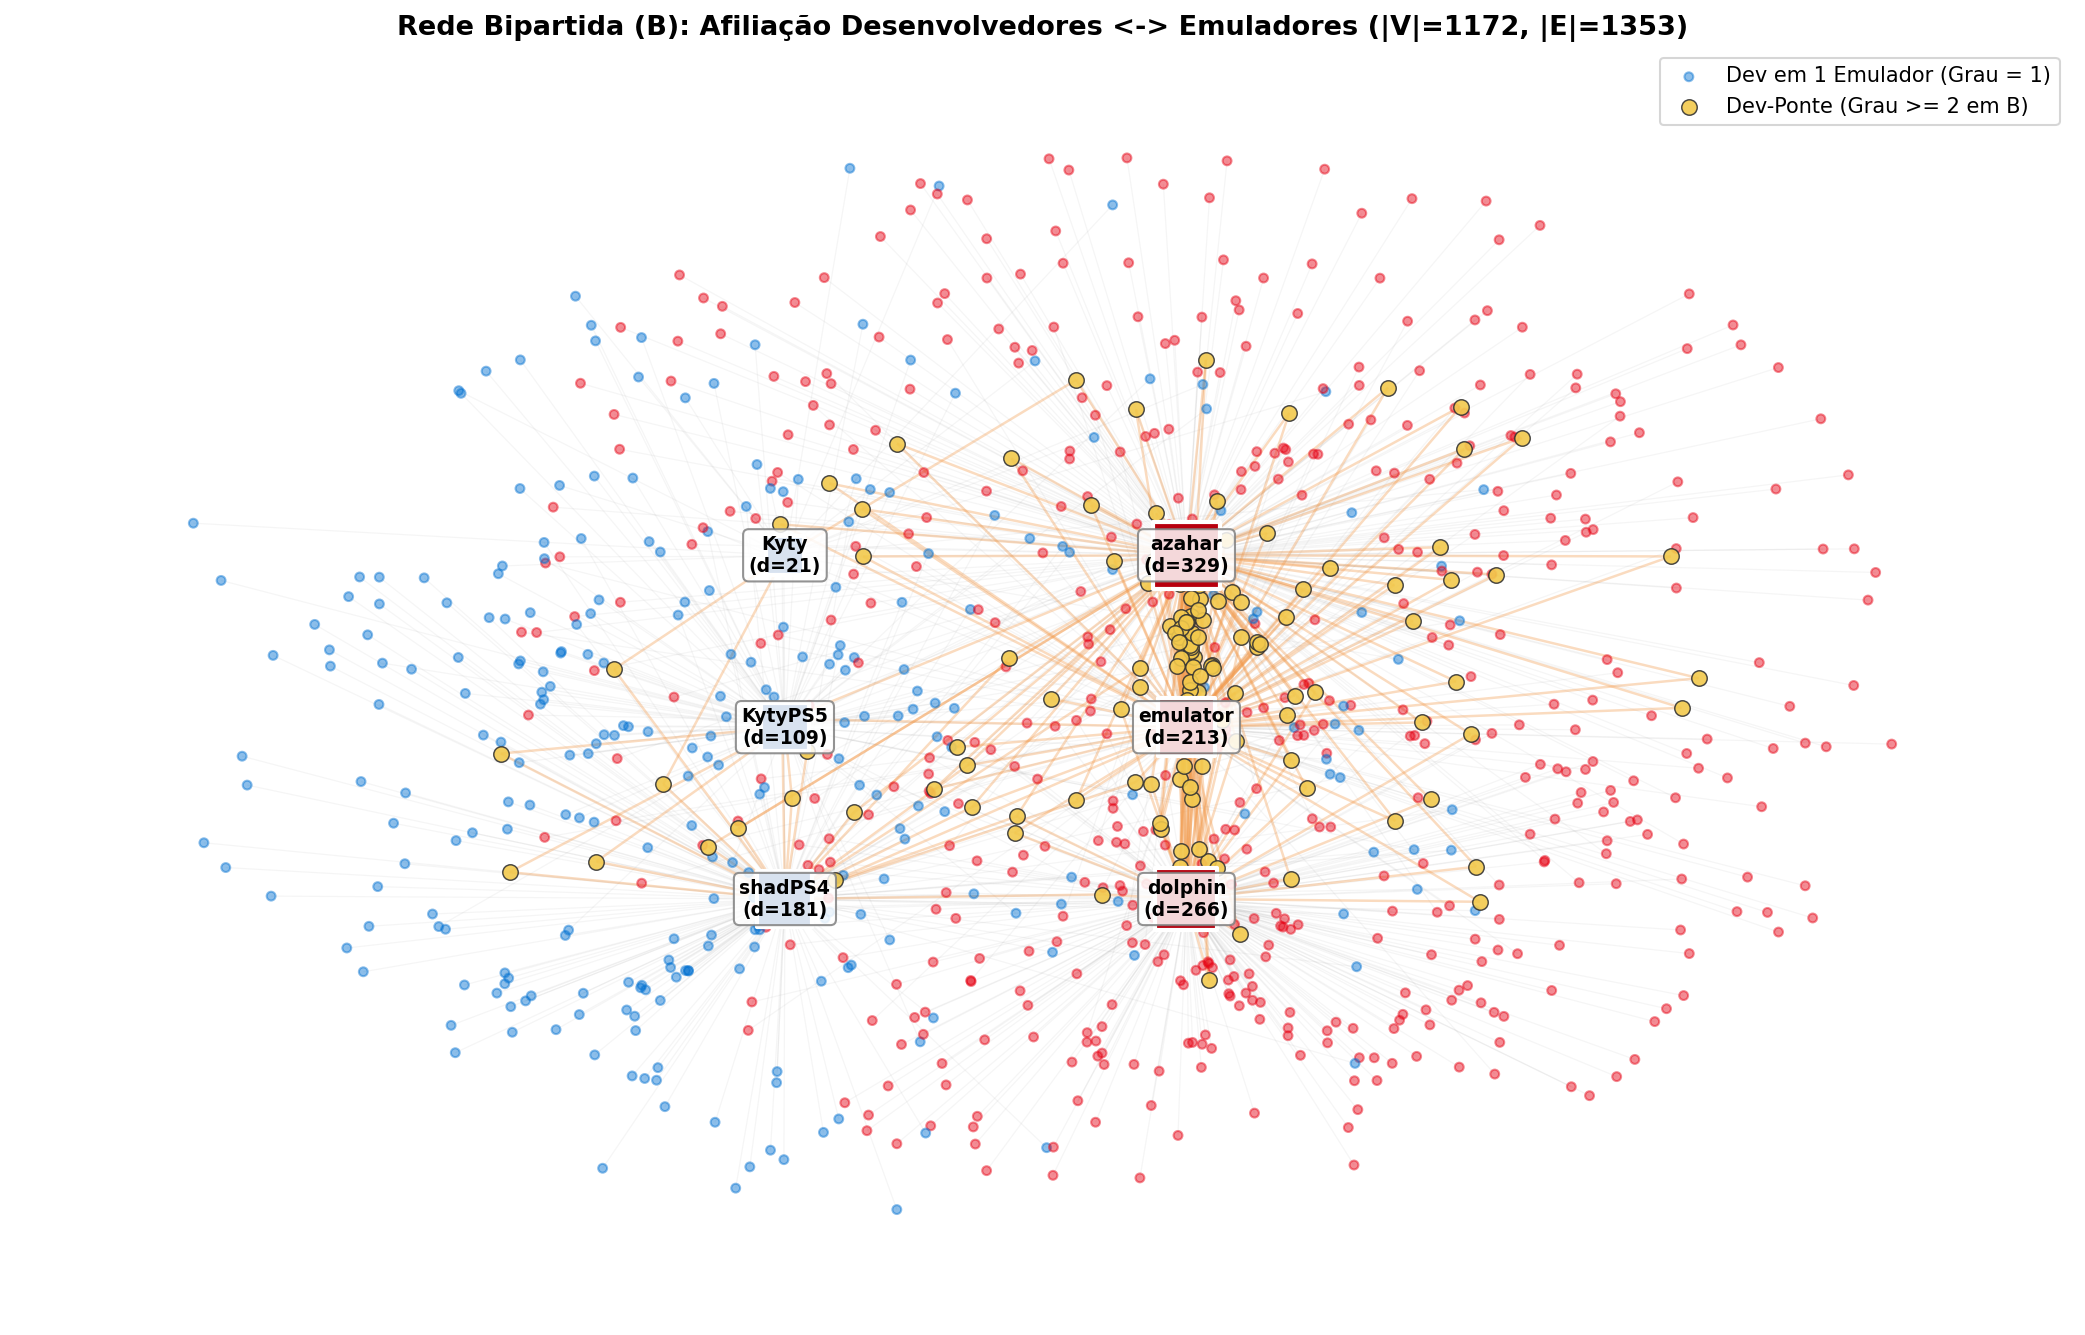

In [ ]:
# FIGURA 1: REDE BIPARTIDA (B) - Desenvolvedores <-> Repositórios
fig, ax = plt.subplots(figsize=(14, 9), dpi=150)

repos_nodes = [n for n, d in B.nodes(data=True) if d.get('tipo') == 'repo']
devs_nodes = [n for n, d in B.nodes(data=True) if d.get('tipo') == 'dev']
devs_ponte_b = [n for n in devs_nodes if B.degree(n) >= 2]
devs_unico_b = [n for n in devs_nodes if B.degree(n) == 1]

# Posicionamento híbrido: Repositórios fixos em duas colunas centrais (PS vs Nintendo)
# e desenvolvedores posicionados via spring_layout ao redor dos repositórios
pos_fixa_repos = {}
ps_repos = sorted([r for r in repos_nodes if B.nodes[r].get('ecossistema') == 0])
nin_repos = sorted([r for r in repos_nodes if B.nodes[r].get('ecossistema') == 1])

for i, r in enumerate(ps_repos):
    pos_fixa_repos[r] = np.array([-0.35, 0.5 - i * 0.5])
for i, r in enumerate(nin_repos):
    pos_fixa_repos[r] = np.array([0.35, 0.5 - i * 0.5])

pos_B = nx.spring_layout(B, pos=pos_fixa_repos, fixed=repos_nodes, k=0.12, iterations=60, seed=42)

# Desenhando arestas de devs exclusivos (bem suaves) e arestas de devs-ponte (destacadas)
arestas_exclusivas = [(u, v) for u, v in B.edges() if (u in devs_unico_b or v in devs_unico_b)]
arestas_ponte = [(u, v) for u, v in B.edges() if (u in devs_ponte_b or v in devs_ponte_b)]

nx.draw_networkx_edges(B, pos_B, edgelist=arestas_exclusivas, alpha=0.08, edge_color="#888888", width=0.6, ax=ax)
nx.draw_networkx_edges(B, pos_B, edgelist=arestas_ponte, alpha=0.35, edge_color="#F2994A", width=1.2, ax=ax)

# Desenhando nós de desenvolvedores (exclusivos vs pontes)
nx.draw_networkx_nodes(
    B, pos_B, nodelist=devs_unico_b,
    node_size=18, alpha=0.45,
    node_color=[CORES_PERFIL[B.nodes[n]['perfil_eco']] for n in devs_unico_b],
    label="Dev em 1 Emulador (Grau = 1)", ax=ax
)
nx.draw_networkx_nodes(
    B, pos_B, nodelist=devs_ponte_b,
    node_size=55, alpha=0.9,
    node_color="#F2C94C", edgecolors="#333333", linewidths=0.7,
    label="Dev-Ponte (Grau >= 2 em B)", ax=ax
)

# Desenhando nós de Repositórios
cores_repos = ["#00439C" if B.nodes[r].get('ecossistema') == 0 else "#B8000E" for r in repos_nodes]
tamanhos_repos = [B.degree(r) * 2.2 + 300 for r in repos_nodes]
nx.draw_networkx_nodes(
    B, pos_B, nodelist=repos_nodes,
    node_size=tamanhos_repos, node_color=cores_repos,
    node_shape="s", edgecolors="white", linewidths=2.0, ax=ax
)

# Rótulos dos repositórios
labels_repos = {r: f"{r.split('/')[-1]}\n(d={B.degree(r)})" for r in repos_nodes}
nx.draw_networkx_labels(
    B, pos_B, labels=labels_repos, font_size=9, font_weight="bold",
    font_color="black", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.85), ax=ax
)

ax.set_title("Rede Bipartida (B): Afiliação Desenvolvedores <-> Emuladores (|V|=1172, |E|=1353)", fontsize=13, fontweight="bold")
ax.axis("off")
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig("figuras/1_rede_bipartida_B.png", dpi=150)
plt.show()

### Projeção Bruta

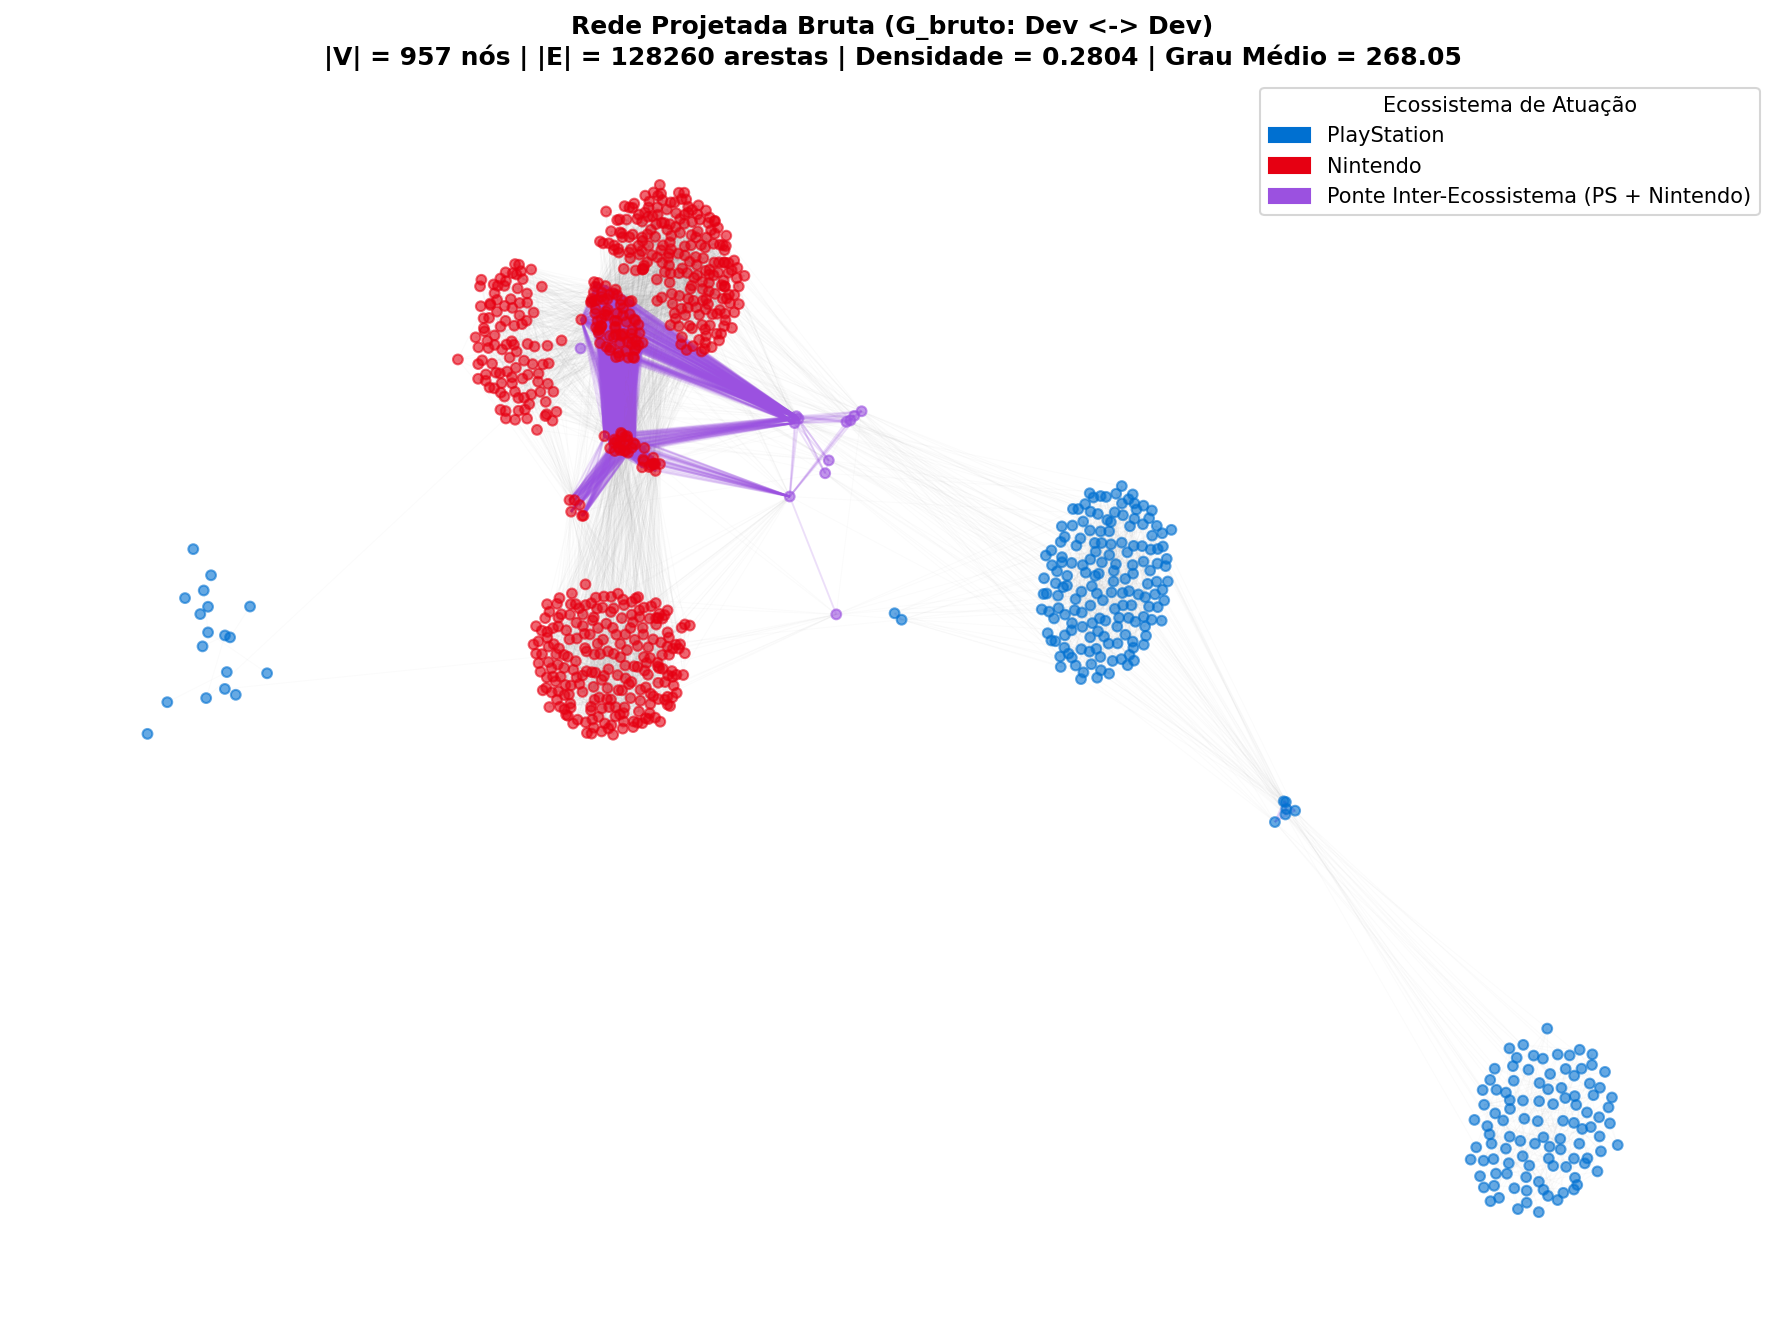

In [ ]:
# FIGURA 2: PROJEÇÃO BRUTA (G_bruto) - Apenas o Grafo da Rede
fig, ax = plt.subplots(figsize=(12, 9), dpi=150)

# Layout de força considerando os pesos para agrupar quem compartilha mais projetos
pos_bruto = nx.spring_layout(G_bruto, weight='weight', k=0.16, iterations=45, seed=42)

# Separando arestas de co-ocorrência única (w = 1) e múltipla (w >= 2)
rng = np.random.default_rng(42)
todas_arestas = list(G_bruto.edges(data=True))
arestas_w1 = [(u, v) for u, v, d in todas_arestas if d.get('weight', 1) == 1]
arestas_w2 = [(u, v) for u, v, d in todas_arestas if d.get('weight', 1) >= 2]

# Amostragem visual das arestas w=1 para evitar sobrecarga gráfica no Matplotlib
amostra_w1_idx = rng.choice(len(arestas_w1), size=min(5000, len(arestas_w1)), replace=False)
amostra_w1 = [arestas_w1[i] for i in amostra_w1_idx]

# 1. Desenhando as arestas (fundo com cliques w=1 e destaque nas conexões w>=2)
nx.draw_networkx_edges(
    G_bruto, pos_bruto, edgelist=amostra_w1,
    alpha=0.03, edge_color="#888888", width=0.5, ax=ax
)
nx.draw_networkx_edges(
    G_bruto, pos_bruto, edgelist=arestas_w2,
    alpha=0.18, edge_color="#9B51E0", width=0.9, ax=ax
)

# 2. Separando nós de devs exclusivos (1 repo) vs devs-ponte (multi_repo == 1)
nos_exclusivos = [n for n, d in G_bruto.nodes(data=True) if d.get('multi_repo', 0) == 0]
nos_ponte_bruto = [n for n, d in G_bruto.nodes(data=True) if d.get('multi_repo', 0) == 1]

# Nós de 1 único repositório (menores e mais translúcidos)
nx.draw_networkx_nodes(
    G_bruto, pos_bruto, nodelist=nos_exclusivos,
    node_size=22,
    node_color=[CORES_PERFIL[G_bruto.nodes[n]['perfil_eco']] for n in nos_exclusivos],
    alpha=0.60, ax=ax
)

# Nós de desenvolvedores-ponte (maiores e com contorno destacado)
nx.draw_networkx_nodes(
    G_bruto, pos_bruto, nodelist=nos_ponte_bruto,
    node_size=60,
    node_color=[CORES_PERFIL[G_bruto.nodes[n]['perfil_eco']] for n in nos_ponte_bruto],
    edgecolors="black", linewidths=0.7, alpha=0.95, ax=ax
)

# Legenda e título informativo com as métricas da rede
patches = [mpatches.Patch(color=cor, label=rotulo) for rotulo, cor in CORES_PERFIL.items()]
ax.legend(handles=patches, loc="upper right", title="Ecossistema de Atuação", frameon=True, fontsize=10)

ax.set_title(
    f"Rede Projetada Bruta (G_bruto: Dev <-> Dev)\n"
    f"|V| = {G_bruto.number_of_nodes()} nós | |E| = {G_bruto.number_of_edges()} arestas | "
    f"Densidade = {nx.density(G_bruto):.4f} | Grau Médio = {sum(dict(G_bruto.degree()).values()) / G_bruto.number_of_nodes():.2f}",
    fontsize=12, fontweight="bold"
)
ax.axis("off")

plt.tight_layout()
plt.savefig("figuras/2_rede_projetada_G_bruto.png", dpi=150)
plt.show()

### Sub-rede de Devs-Pontes

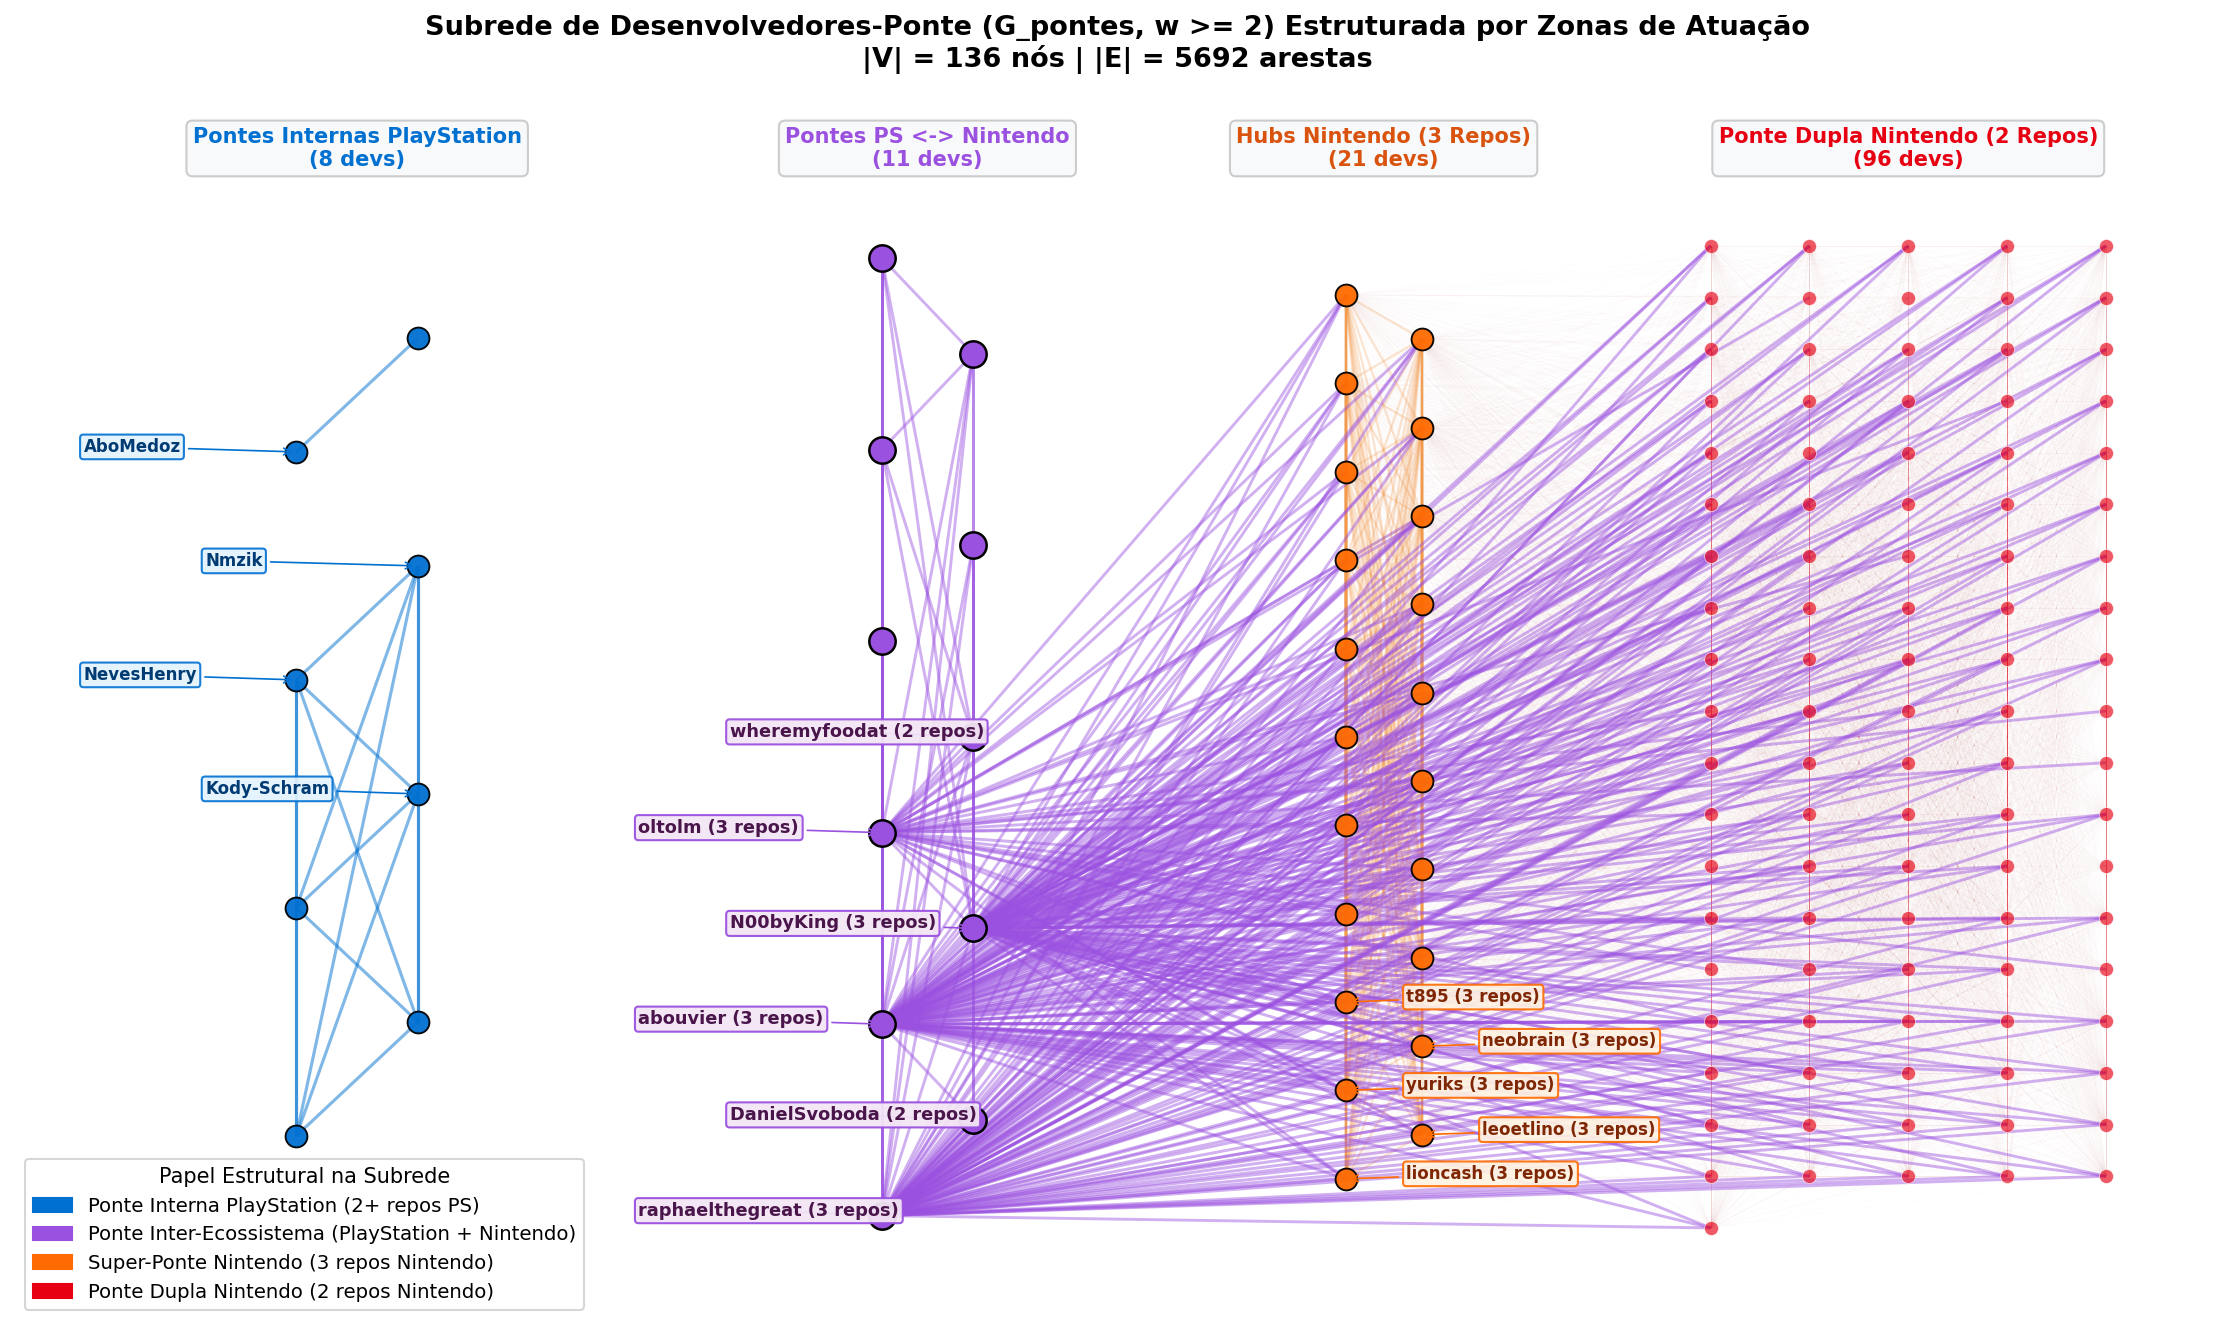

In [ ]:
# Mapeamento direto a partir de nodes_df e bipartite_df para não depender de células anteriores
mapa_nomes = nodes_df.set_index('id')['name'].to_dict()
mapa_num_repos = nodes_df.set_index('id')['num_repos'].to_dict()
mapa_interacoes = nodes_df.set_index('id')['total_interacoes'].to_dict()
ecos_por_dev = bipartite_df.groupby('dev_id')['ecossistema'].unique().to_dict()

def obter_perfil_eco(dev_id):
    ecos = set(ecos_por_dev.get(dev_id, []))
    if len(ecos) > 1:
        return "Ponte Inter-Ecossistema (PS + Nintendo)"
    elif 1 in ecos:
        return "Nintendo"
    return "PlayStation"

for n in G_pontes.nodes():
    G_pontes.nodes[n]['name'] = mapa_nomes.get(n, f"Dev_{n}")
    G_pontes.nodes[n]['num_repos'] = mapa_num_repos.get(n, 2)
    G_pontes.nodes[n]['total_interacoes'] = mapa_interacoes.get(n, 1)
    G_pontes.nodes[n]['perfil_eco'] = obter_perfil_eco(n)

# 2. Layout Estruturado por Zonas
nos_ps = [n for n, d in G_pontes.nodes(data=True) if d['perfil_eco'] == "PlayStation"]
nos_inter = [n for n, d in G_pontes.nodes(data=True) if d['perfil_eco'] == "Ponte Inter-Ecossistema (PS + Nintendo)"]
nos_nin_3 = [n for n, d in G_pontes.nodes(data=True) if d['perfil_eco'] == "Nintendo" and d['num_repos'] >= 3]
nos_nin_2 = [n for n, d in G_pontes.nodes(data=True) if d['perfil_eco'] == "Nintendo" and d['num_repos'] == 2]

pos_pontes = {}

# Zona 1 (Esquerda: x = -1.0): Devs-Ponte internos da PlayStation
for i, n in enumerate(sorted(nos_ps, key=lambda x: G_pontes.degree(x), reverse=True)):
    y = np.linspace(-0.65, 0.65, max(len(nos_ps), 1))[i]
    x_offset = -0.08 if i % 2 == 0 else 0.08
    pos_pontes[n] = np.array([-1.0 + x_offset, y])

# Zona 2 (Centro: x = -0.25): Devs-Ponte Inter-Ecossistema (PS + Nintendo)
for i, n in enumerate(sorted(nos_inter, key=lambda x: G_pontes.nodes[x]['total_interacoes'], reverse=True)):
    y = np.linspace(-0.78, 0.78, max(len(nos_inter), 1))[i]
    x_offset = -0.06 if i % 2 == 0 else 0.06
    pos_pontes[n] = np.array([-0.25 + x_offset, y])

# Zona 3 (Centro-Direita: x = 0.35): Hubs Nintendo que atuam em 3 emuladores
for i, n in enumerate(sorted(nos_nin_3, key=lambda x: G_pontes.nodes[x]['total_interacoes'], reverse=True)):
    y = np.linspace(-0.72, 0.72, max(len(nos_nin_3), 1))[i]
    x_offset = -0.05 if i % 2 == 0 else 0.05
    pos_pontes[n] = np.array([0.35 + x_offset, y])

# Zona 4 (Direita: x de 0.75 a 1.35): Clique Nintendo de 2 emuladores (distribuídos em grade limpa)
n_cols = 5
for i, n in enumerate(sorted(nos_nin_2, key=lambda x: G_pontes.nodes[x]['total_interacoes'], reverse=True)):
    col = i % n_cols
    row = i // n_cols
    total_rows = max((len(nos_nin_2) - 1) // n_cols + 1, 1)
    x = 0.78 + col * 0.13
    y = 0.80 - (row / max(total_rows - 1, 1)) * 1.60
    pos_pontes[n] = np.array([x, y])

fig, ax = plt.subplots(figsize=(15, 9), dpi=150)

# Separando as arestas por relevância estrutural para não poluir o fundo
arestas_inter = [(u, v) for u, v in G_pontes.edges() if (u in nos_inter or v in nos_inter)]
arestas_ps = [(u, v) for u, v in G_pontes.edges() if (u in nos_ps and v in nos_ps)]
arestas_w3 = [(u, v) for u, v, d in G_pontes.edges(data=True) if d.get('weight', 2) >= 3 and u not in nos_inter and v not in nos_inter]
arestas_clique_w2 = [(u, v) for u, v, d in G_pontes.edges(data=True) if d.get('weight', 2) == 2 and u not in nos_inter and v not in nos_inter and u not in nos_ps]

# Desenhando arestas em camadas de opacidade
nx.draw_networkx_edges(G_pontes, pos_pontes, edgelist=arestas_clique_w2, alpha=0.015, edge_color="#E60012", width=0.4, ax=ax)
nx.draw_networkx_edges(G_pontes, pos_pontes, edgelist=arestas_w3, alpha=0.25, edge_color="#F2994A", width=1.1, ax=ax)
nx.draw_networkx_edges(G_pontes, pos_pontes, edgelist=arestas_ps, alpha=0.50, edge_color="#0070D1", width=1.5, ax=ax)
nx.draw_networkx_edges(G_pontes, pos_pontes, edgelist=arestas_inter, alpha=0.45, edge_color="#9B51E0", width=1.4, ax=ax)

# Desenhando os nós por grupo
nx.draw_networkx_nodes(G_pontes, pos_pontes, nodelist=nos_nin_2, node_size=45, node_color="#E60012", alpha=0.65, edgecolors="white", linewidths=0.4, ax=ax)
nx.draw_networkx_nodes(G_pontes, pos_pontes, nodelist=nos_nin_3, node_size=110, node_color="#FF6B00", alpha=0.95, edgecolors="black", linewidths=0.9, ax=ax)
nx.draw_networkx_nodes(G_pontes, pos_pontes, nodelist=nos_ps, node_size=110, node_color="#0070D1", alpha=0.95, edgecolors="black", linewidths=0.9, ax=ax)
nx.draw_networkx_nodes(G_pontes, pos_pontes, nodelist=nos_inter, node_size=160, node_color="#9B51E0", alpha=1.0, edgecolors="black", linewidths=1.2, ax=ax)

# Rotulando os principais nós de cada zona (sem empilhar textos!)
# 1) Top 6 Pontes Inter-Ecossistema (Roxo)
top_inter = sorted(nos_inter, key=lambda x: (G_pontes.nodes[x]['num_repos'], G_pontes.nodes[x]['total_interacoes']), reverse=True)[:6]
for n in top_inter:
    x, y = pos_pontes[n]
    nome = G_pontes.nodes[n]['name']
    repos = G_pontes.nodes[n]['num_repos']
    ax.annotate(
        f"{nome} ({repos} repos)", xy=(x, y), xytext=(x - 0.32, y),
        fontsize=8.5, fontweight="bold", color="#4A154B",
        bbox=dict(boxstyle="round,pad=0.2", fc="#F3E5F5", ec="#9B51E0", alpha=0.95),
        arrowprops=dict(arrowstyle="->", color="#9B51E0", lw=0.8)
    )

# 2) Top 4 Pontes PlayStation (Azul)
top_ps = sorted(nos_ps, key=lambda x: (G_pontes.nodes[x]['num_repos'], G_pontes.nodes[x]['total_interacoes']), reverse=True)[:4]
for n in top_ps:
    x, y = pos_pontes[n]
    nome = G_pontes.nodes[n]['name']
    ax.annotate(
        f"{nome}", xy=(x, y), xytext=(x - 0.28, y),
        fontsize=8, fontweight="bold", color="#003B73",
        bbox=dict(boxstyle="round,pad=0.2", fc="#E3F2FD", ec="#0070D1", alpha=0.9),
        arrowprops=dict(arrowstyle="->", color="#0070D1", lw=0.8)
    )

# 3) Top 5 Super-Hubs Nintendo (Laranja - 3 repos)
top_nin3 = sorted(nos_nin_3, key=lambda x: (G_pontes.nodes[x]['num_repos'], G_pontes.nodes[x]['total_interacoes']), reverse=True)[:5]
for n in top_nin3:
    x, y = pos_pontes[n]
    nome = G_pontes.nodes[n]['name']
    repos = G_pontes.nodes[n]['num_repos']
    ax.annotate(
        f"{nome} ({repos} repos)", xy=(x, y), xytext=(x + 0.08, y),
        fontsize=8, fontweight="bold", color="#7F2704",
        bbox=dict(boxstyle="round,pad=0.2", fc="#FFF3E0", ec="#FF6B00", alpha=0.9),
        arrowprops=dict(arrowstyle="->", color="#FF6B00", lw=0.8)
    )

# Títulos de coluna no topo do gráfico para guiar a leitura imediata
estilo_header = dict(fontsize=10, fontweight="bold", ha="center", bbox=dict(boxstyle="round,pad=0.3", fc="#F8F9FA", ec="#CCCCCC"))
ax.text(-1.0, 0.93, f"Pontes Internas PlayStation\n({len(nos_ps)} devs)", color="#0070D1", **estilo_header)
ax.text(-0.25, 0.93, f"Pontes PS <-> Nintendo\n({len(nos_inter)} devs)", color="#9B51E0", **estilo_header)
ax.text(0.35, 0.93, f"Hubs Nintendo (3 Repos)\n({len(nos_nin_3)} devs)", color="#D9530F", **estilo_header)
ax.text(1.04, 0.93, f"Ponte Dupla Nintendo (2 Repos)\n({len(nos_nin_2)} devs)", color="#E60012", **estilo_header)

# Legenda limpa
legenda_items = [
    mpatches.Patch(color="#0070D1", label="Ponte Interna PlayStation (2+ repos PS)"),
    mpatches.Patch(color="#9B51E0", label="Ponte Inter-Ecossistema (PlayStation + Nintendo)"),
    mpatches.Patch(color="#FF6B00", label="Super-Ponte Nintendo (3 repos Nintendo)"),
    mpatches.Patch(color="#E60012", label="Ponte Dupla Nintendo (2 repos Nintendo)")
]
ax.legend(handles=legenda_items, loc="lower left", frameon=True, fontsize=9.5, title="Papel Estrutural na Subrede")

ax.set_xlim(-1.45, 1.45)
ax.set_ylim(-0.95, 1.05)
ax.set_title(
    f"Subrede de Desenvolvedores-Ponte (G_pontes, w >= 2) Estruturada por Zonas de Atuação\n"
    f"|V| = {G_pontes.number_of_nodes()} nós | |E| = {G_pontes.number_of_edges()} arestas",
    fontsize=13, fontweight="bold", pad=12
)
ax.axis("off")

plt.tight_layout()
plt.savefig("figuras/3_subrede_devs_ponte_G_pontes.png", dpi=150)
plt.show()

## 3.2 Análise Estrutural

Apesar das figuras auxiliarem na compreensão do problema, é necessário fazer uma análise mais profunda para poder identificar de forma quantitativa como a sobreposição de desenvolvedores ocorre.

Para entender isso e quem são os principais contribuidores-ponte, aplicamos o ferramental observado em aula, comparando o comportamento da rede antes e depois da filtragem por limiar:

1. **Travessia, Mundo Pequeno e Componentes Conectadas:** Avaliamos a formação da **Componente Gigante (GCC)**, **diâmetro**, **distância média (via BFS)**, **eficiência global** e **coeficiente de clustering (triângulos)**. Demonstramos como o corte do *Esqueleto por Limiar* ($w \ge 2$) fragmenta a subrede `G_pontes` em 3 componentes, separando as pontes internas da PlayStation da componente gigante conectada à Nintendo.
2. **Centralidades e Identificação de Hubs/Pontes:** Combinamos quatro medidas complementares traduzidas para o domínio de emuladores:
   * **Centralidade de Grau (*Degree*):** Mede o alcance direto de co-atuação do desenvolvedor.
   * **Centralidade de Intermediação (*Betweenness*):** Identifica os **verdadeiros corretores (*brokers*) inter-ecossistema**, que ficam no caminho mínimo entre os desenvolvedores exclusivos da PlayStation e da Nintendo.
   * **Centralidade de Proximidade (*Closeness*):** Aponta os desenvolvedores capazes de difundir código/conhecimento mais rápido por toda a rede.
   * **Centralidade de Vetor Próprio (*Eigenvector*):** Destaca a elite altamente conectada dentro do núcleo mais denso (comunidade Nintendo).Para este problema, como o peso $w$ das nossas arestas mede **afinidade** (co-ocorrência), definimos a distância topológica como $d(u,v) = \frac{1}{w(u,v)}$ para o cálculo exato de caminhos mínimos em *Betweenness* e *Closeness*, mantendo $w(u,v)$ direto para *Eigenvector*.
3. **Decomposição em Núcleos e Estrutura Núcleo-Periferia (Semanas 3 e 5):** Calculamos a **degenerescência (*degeneracy*)**, o ***core number*** ($k$-core / $k$-shell) e as **camadas de cebola (*onion layers*)** para separar a periferia de contribuidores casuais do núcleo mais denso de colaboração multi-emulador.

### Componentes (GCC), Mundo Pequeno, Distâncias e Clustering

In [ ]:
# COMPONENTES CONECTADAS (GCC), DISTÂNCIAS, EFICIÊNCIA E CLUSTERING

# Garantindo atributo de distância = 1 / weight para algoritmos de caminho mínimo
for grafo in [B, G_bruto, G_pontes]:
    for u, v, d in grafo.edges(data=True):
        peso = d.get('weight', 1)
        d['distancia'] = 1.0 / peso if peso > 0 else 1.0

def analisar_estrutura_e_navegacao(G, nome_rede, eh_bipartida=False):
    # Componentes Conectadas
    componentes = sorted(nx.connected_components(G), key=len, reverse=True)
    num_comp = len(componentes)
    gcc_nodes = componentes[0]
    G_gcc = G.subgraph(gcc_nodes).copy()

    # Caminho mínimo médio e Diâmetro na GCC (via BFS)
    if G_gcc.number_of_nodes() > 1:
        dist_media = nx.average_shortest_path_length(G_gcc)
        diametro = nx.diameter(G_gcc)
    else:
        dist_media, diametro = 0, 0

    # Eficiência Global e Coeficiente de Clustering / Triângulos
    eficiencia = nx.global_efficiency(G)
    if eh_bipartida:
        # Em grafos bipartidos puros não há triângulos (clustering padrão = 0),
        # usa-se o clustering bipartido de Latapy (quadriláteros)
        clustering_medio = nx.bipartite.average_clustering(G)
        total_triangulos = 0
    else:
        clustering_medio = nx.average_clustering(G)
        total_triangulos = sum(nx.triangles(G).values()) // 3

    return {
        "Rede": nome_rede,
        "Nós (|V|)": G.number_of_nodes(),
        "Componentes (WCC)": num_comp,
        "Tamanho da GCC": f"{len(gcc_nodes)} ({len(gcc_nodes)/G.number_of_nodes()*100:.1f}%)",
        "Distância Média (GCC)": round(dist_media, 3),
        "Diâmetro (GCC)": diametro,
        "Eficiência Global": round(eficiencia, 4),
        "Clustering Médio": round(clustering_medio, 4),
        "Triângulos": total_triangulos
    }

df_navegacao = pd.DataFrame([
    analisar_estrutura_e_navegacao(B, "1. Bipartida (B)", eh_bipartida=True),
    analisar_estrutura_e_navegacao(G_bruto, "2. Projeção Bruta (G_bruto)"),
    analisar_estrutura_e_navegacao(G_pontes, "3. Subrede de Pontes (G_pontes, w>=2)")
])

print("=== MÉTRICAS DE TRAVESSIA, MUNDO PEQUENO E COMPONENTES ===")
display(df_navegacao)

# Detalhando as Componentes Conectadas de G_pontes (explica as ilhas vistas no gráfico!)
print("\n=== INSPEÇÃO DAS COMPONENTES CONECTADAS EM G_pontes ===")
for idx, comp in enumerate(sorted(nx.connected_components(G_pontes), key=len, reverse=True), 1):
    sub = G_pontes.subgraph(comp)
    perfis = pd.Series([G_pontes.nodes[n].get('perfil_eco', 'N/A') for n in comp]).value_counts().to_dict()
    exemplos_nomes = [G_pontes.nodes[n].get('name', str(n)) for n in list(comp)[:5]]
    emuladores_comp = set()
    for n in comp:
        emus = G_pontes.nodes[n].get('emuladores', '')
        if emus:
            emuladores_comp.update(emus.split('|'))
    print(f"Componente {idx}: {len(comp)} nós e {sub.number_of_edges()} arestas")
    print(f"   -> Perfis: {perfis}")
    print(f"   -> Emuladores envolvidos: {sorted(emuladores_comp)}")
    print(f"   -> Exemplos de Devs: {', '.join(exemplos_nomes)}\n")

=== MÉTRICAS DE TRAVESSIA, MUNDO PEQUENO E COMPONENTES (SEMANAS 3 E 4) ===


,Rede,Nós (|V|),Componentes (WCC),Tamanho da GCC,Distância Média (GCC),Diâmetro (GCC),Eficiência Global,Clustering Médio,Triângulos
0,1. Bipartida (B),963,1,963 (100.0%),3.760,6,0.3079,0.8192,0
1,2. Projeção Bruta (G_bruto),957,1,957 (100.0%),1.884,3,0.6127,0.9502,11582259
2,"3. Subrede de Pontes (G_pontes, w>=2)",136,3,128 (94.1%),1.320,3,0.7509,0.9386,178096



=== INSPEÇÃO DAS COMPONENTES CONECTADAS EM G_pontes (SEMANA 4) ===
Componente 1: 128 nós e 5676 arestas
   -> Perfis: {'Nintendo': 117, 'Ponte Inter-Ecossistema (PS + Nintendo)': 11}
   -> Emuladores envolvidos: ['azahar-emu/azahar', 'citron-neo/emulator', 'dolphin-emu/dolphin', 'shadps4-emu/shadPS4']
   -> Exemplos de Devs: cscd98, daniellimws, danilaml, darkf, ds84182

Componente 2: 6 nós e 15 arestas
   -> Perfis: {'PlayStation': 6}
   -> Emuladores envolvidos: ['KytyPS5/KytyPS5', 'shadps4-emu/shadPS4']
   -> Exemplos de Devs: NevesHenry, Aspenini, Nmzik, Kody-Schram, C0rn3j

Componente 3: 2 nós e 1 arestas
   -> Perfis: {'PlayStation': 2}
   -> Emuladores envolvidos: ['InoriRus/Kyty', 'shadps4-emu/shadPS4']
   -> Exemplos de Devs: Mored4u, AboMedoz



### 3.2.1 Análise dos Resultados: Travessia, Mundo Pequeno, Clustering e Componentes

A comparação das métricas topológicas entre a **Rede Bipartida (`B`)**, a **Projeção Bruta (`G_bruto`)** e a **Subrede de Pontes (`G_pontes`)** evidencia tanto a estrutura real da colaboração entre os ecossistemas quanto os artefatos matemáticos decorrentes das escolhas de modelagem:

#### 1. Distâncias, Diâmetro e o Efeito de Mundo Pequeno
* Observa-se que a **Distância Média** cai exatamente pela metade ao passarmos da rede bipartida (`3,760`) para a projeção bruta (`1,884`), o mesmo ocorrendo com o **Diâmetro**, que passa de 6 em `B` para 3 em `G_bruto`. Isso reflete a propriedade estrutural da projeção unipartida: cada passo direto entre dois desenvolvedores em `G_bruto` equivale a uma caminhada de comprimento $2$ (`Dev -> Repo -> Dev`) na rede bipartida original.
* Ambas as redes (`B` e `G_bruto`) possuem uma única Componente Gigante (GCC) abrangendo 100% dos nós (`963` e `957` nós, respectivamente). O Diâmetro igual a 3 em `G_bruto` demonstra que a rede apresenta forte característica de Mundo Pequeno: mesmo desenvolvedores situados em extremos opostos e sem interseção direta (como colaboradores exclusivos do `InoriRus/Kyty` na PlayStation) estão a no máximo 3 saltos de distância, intermediados por hubs como `shadPS4` e `azahar`.
* Quando isolamos a subrede de desenvolvedores que compartilham ao menos dois projetos (`G_pontes`), a Eficiência Global atinge seu valor máximo (`0,7509`, frente a `0,6127` em `G_bruto` e `0,3079` em `B`), com uma Distância Média de apenas `1,320` na sua componente principal. Isso comprova que o grupo de contribuidores multi-projeto forma um núcleo altamente integrado para troca de soluções técnicas.

#### 2. Coeficiente de Clustering e Triângulos: Senso Crítico sobre o Artefato de Projeção
* Em `B`, a contagem de triângulos é `0`, visto que grafos bipartidos não admitem ciclos de comprimento ímpar. O elevado Clustering Médio (`0,8192`) refere-se ao coeficiente bipartido de Latapy, que captura a densidade de ciclos de comprimento 4 (duplas de desenvolvedores vinculadas aos mesmos repositórios).
* Na projeção bruta, o Clustering Médio sobe para `0,9502` acompanhado de 11.582.259 triângulos. Sob uma ótica crítica de modelagem, esse volume é um artefato da projeção: como cada emulador de tamanho $n$ é projetado como uma clique completa ($K_n$), ele adiciona $\binom{n}{3}$ triângulos mesmo entre usuários casuais que atuaram em apenas um repositório.
* Ao aplicarmos o corte do *Esqueleto por Limiar* ($w \ge 2$), eliminamos 98,46% dos triângulos artificiais (reduzindo para 178.096 triângulos). Ainda assim, o Clustering Médio mantém-se em `0,9386`, provando que os desenvolvedores-ponte não realizam conexões esparsas ou acidentais, mas formam subcomunidades densas de múltipla co-atuação (impulsionadas sobretudo pelos `102` desenvolvedores comuns entre `azahar` e `citron-neo`).

#### 3. Componentes Conectadas (`WCC`) e o Isolamento Estrutural da PlayStation
A inspeção das componentes em `G_pontes` ($w \ge 2$) revela por que a subrede se divide em 3 componentes conectadas e explica a topologia observada nos gráficos:
1. **Componente 1 (GCC — `128` nós / `94,1%` e `5.676` arestas):** Concentra todos os **117 desenvolvedores-ponte da Nintendo** e os **11 desenvolvedores Ponte Inter-Ecossistema (`PS + Nintendo`)**.
2. **Componente 2 (Ilha PlayStation 1 — `6` nós e `15` arestas):** Forma uma clique perfeita $K_6$ composta por **6 desenvolvedores exclusivos da PlayStation** que contribuíram conjuntamente em `KytyPS5` e `shadPS4`.
3. **Componente 3 (Ilha PlayStation 2 — `2` nós e `1` aresta):** Forma um par conectado ($K_2$) composto por **2 desenvolvedores exclusivos da PlayStation** que atuaram em `InoriRus/Kyty` e `shadPS4`.

* **Por que as Componentes 2 e 3 se desprenderam da GCC se todas participam do `shadPS4`?** Embora os desenvolvedores das Componentes 2 e 3 coexistam com as 11 pontes Inter-Ecossistema dentro do `shadPS4`, eles compartilham **apenas 1 repositório em comum** com elas (`shadPS4`). Como o limiar de `G_pontes` exige $w \ge 2$ (pelo menos 2 emuladores compartilhados pelo mesmo par de desenvolvedores), todas as arestas que ligavam essas duas ilhas da PlayStation ao restante da rede tinham peso $w = 1$ e foram removidas no corte do esqueleto.

### Centralidades: Grau, Closeness, Betweenness e Eigenvector

Cálculo concluído em 10.10 segundos para 137 desenvolvedores-ponte!

=== TOP 10 DESENVOLVEDORES-PONTE POR BETWEENNESS (INTERMEDIAÇÃO ENTRE ECOSSISTEMAS) ===


,Desenvolvedor,Perfil Ecossistema,Nº Emuladores,Emuladores,Betweenness (G_pontes w>=2),Betweenness (Pontes w>=1),Betweenness (Bipartida B)
116,raphaelthegreat,Ponte Inter-Ecossistema (PS + Nintendo),3,azahar-emu/azahar|citron-neo/emulator|shadps4-...,0.02427,0.04650,0.42743
40,N00byKing,Ponte Inter-Ecossistema (PS + Nintendo),3,azahar-emu/azahar|citron-neo/emulator|shadps4-...,0.02427,0.04650,0.00000
57,abouvier,Ponte Inter-Ecossistema (PS + Nintendo),3,azahar-emu/azahar|citron-neo/emulator|shadps4-...,0.02427,0.04650,0.00000
114,oltolm,Ponte Inter-Ecossistema (PS + Nintendo),3,azahar-emu/azahar|dolphin-emu/dolphin|shadps4-...,0.02252,0.02824,0.00000
102,lioncash,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.38724
4,CarlKenner,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.00000
7,CookiePLMonster,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.00000
13,DimitriPilot3,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.00000
32,KAMiKAZOW,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.00000
62,archshift,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.00914,0.00878,0.00000



=== TOP 10 DESENVOLVEDORES-PONTE POR EIGENVECTOR (INFLUÊNCIA NO NÚCLEO DENSO DE G_pontes) ===


,Desenvolvedor,Perfil Ecossistema,Nº Emuladores,Emuladores,Eigenvector (G_pontes),Degree Centrality (G_pontes),Closeness (G_pontes)
4,CarlKenner,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
7,CookiePLMonster,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
127,v1993,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
135,yuriks,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
62,archshift,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
65,bentley,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
71,comex,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
32,KAMiKAZOW,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
13,DimitriPilot3,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766
134,xsacha,Nintendo,3,azahar-emu/azahar|citron-neo/emulator|dolphin-...,0.11004,0.8889,1.8766


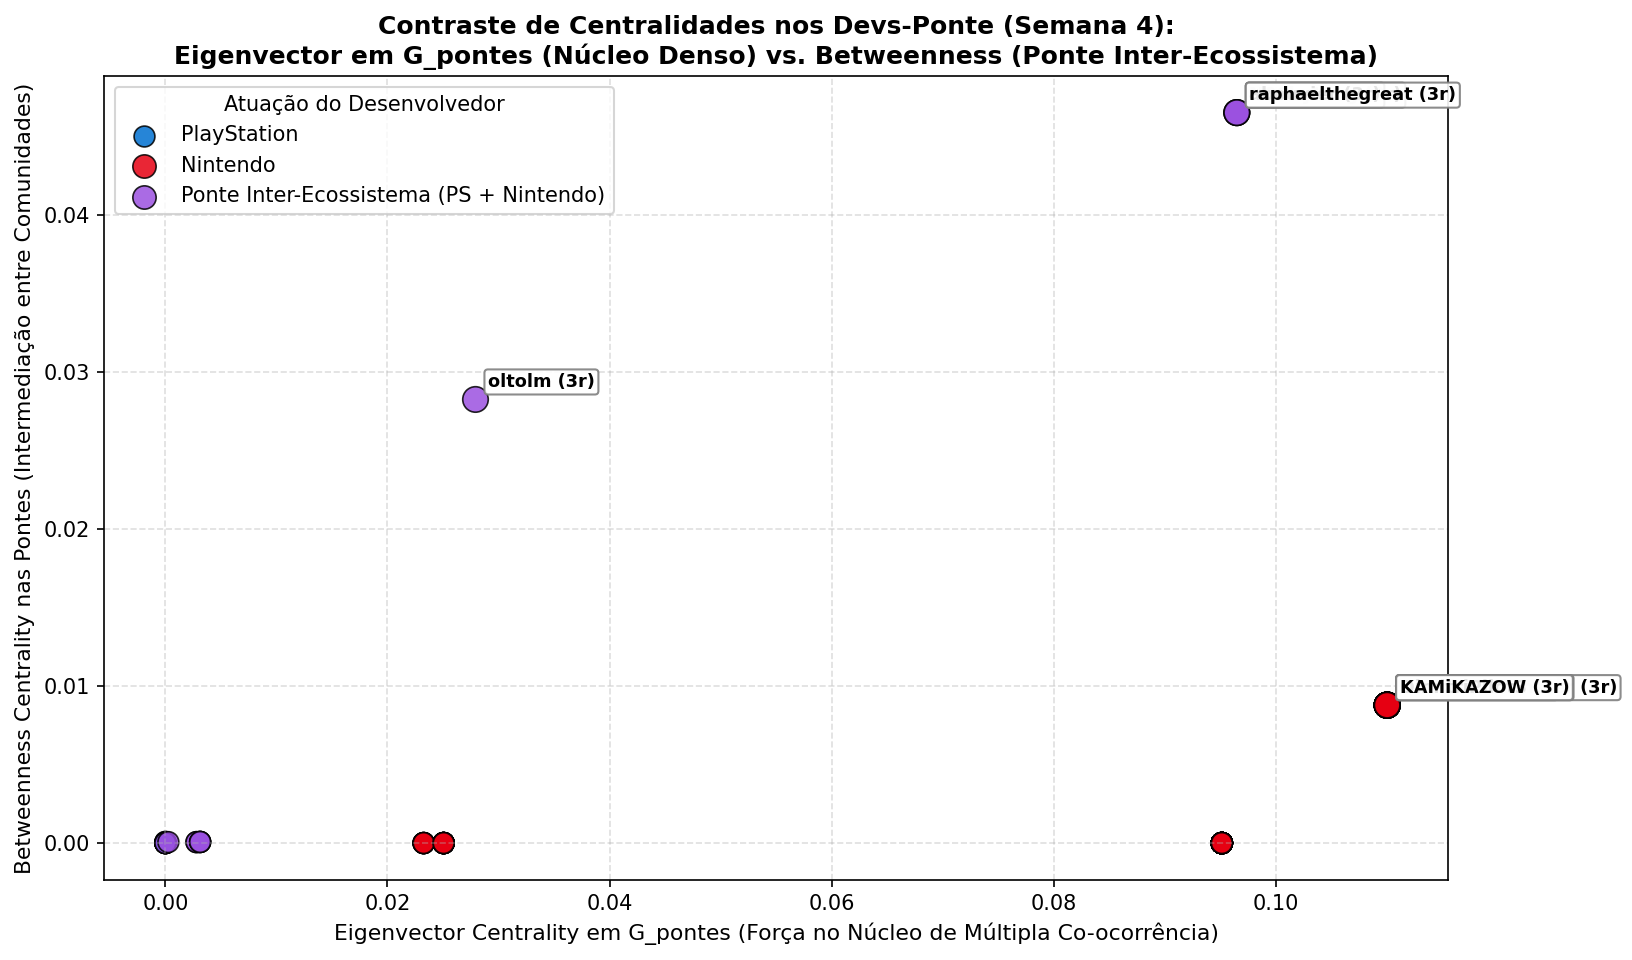

In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# CENTRALIDADES: FOCO EM G_pontes E NA REDE BIPARTIDA B
inicio = time.time()

# 1. Sincronizando atributos a partir de nodes_df e bipartite_df (evita dicionários vazios)
atributos_nodes = nodes_df.set_index('id').to_dict('index')
resumo_part = (
    bipartite_df.groupby('dev_id')
    .agg(
        emuladores=('repo', lambda s: "|".join(sorted(set(s)))),
        num_repos_real=('repo', 'nunique'),
        peso_total=('peso', 'sum')
    )
    .to_dict('index')
)
ecos_por_dev = bipartite_df.groupby('dev_id')['ecossistema'].unique().to_dict()

def obter_perfil_eco(dev_id):
    ecos = set(ecos_por_dev.get(int(dev_id), []))
    if len(ecos) > 1:
        return "Ponte Inter-Ecossistema (PS + Nintendo)"
    elif 1 in ecos:
        return "Nintendo"
    return "PlayStation"

# Garantindo que G_bruto e G_pontes tenham todos os atributos atualizados
for grafo in [G_bruto, G_pontes]:
    for n in grafo.nodes():
        n_int = int(n)
        if n_int in atributos_nodes:
            grafo.nodes[n].update(atributos_nodes[n_int])
        if n_int in resumo_part:
            grafo.nodes[n].update(resumo_part[n_int])
        grafo.nodes[n]['perfil_eco'] = obter_perfil_eco(n_int)

# 2. Identificando todos os devs-ponte diretamente pelo bipartite_df (>= 2 repos) ou presentes em G_pontes
nos_todos_pontes = sorted(
    set(
        [n for n in G_bruto.nodes() if resumo_part.get(int(n), {}).get('num_repos_real', 1) >= 2]
        + list(G_pontes.nodes())
    )
)

# Subrede com todos os devs-ponte (incluindo arestas w >= 1 entre eles)
G_pontes_w1 = G_bruto.subgraph(nos_todos_pontes).copy()

# Definindo distância = 1 / weight para os algoritmos de caminho mínimo
for grafo in [B, G_pontes, G_pontes_w1]:
    for u, v, d in grafo.edges(data=True):
        peso = d.get('weight', 1)
        d['distancia'] = 1.0 / peso if peso > 0 else 1.0

# 3. Calculando as 4 Centralidades em G_pontes (w >= 2), G_pontes_w1 (w >= 1) e Bipartida (B)
deg_pontes = nx.degree_centrality(G_pontes)
clos_pontes = nx.closeness_centrality(G_pontes, distance='distancia')
bet_pontes = nx.betweenness_centrality(G_pontes, weight='distancia', normalized=True)
eig_pontes = nx.eigenvector_centrality(G_pontes, weight='weight', max_iter=1000)

bet_pontes_w1 = nx.betweenness_centrality(G_pontes_w1, weight='distancia', normalized=True)
bet_bipartida = nx.betweenness_centrality(B, weight='distancia', normalized=True)

tempo_total = time.time() - inicio
print(f"Cálculo concluído em {tempo_total:.2f} segundos para {len(nos_todos_pontes)} desenvolvedores-ponte!")

# 4. Construindo o DataFrame de Centralidades
registros_centralidade = []
for n in nos_todos_pontes:
    n_int = int(n)
    d = G_bruto.nodes[n]
    node_b_id = f"dev_{n_int}" if f"dev_{n_int}" in B else n_int

    registros_centralidade.append({
        "ID": n,
        "Desenvolvedor": d.get('name', f"Dev_{n_int}"),
        "Perfil Ecossistema": d.get('perfil_eco', obter_perfil_eco(n_int)),
        "Nº Emuladores": d.get('num_repos', d.get('num_repos_real', 2)),
        "Total Interações": d.get('total_interacoes', d.get('peso_total', 1)),
        "Emuladores": d.get('emuladores', ''),
        "Grau (G_pontes w>=2)": G_pontes.degree(n) if n in G_pontes else 0,
        "Degree Centrality (G_pontes)": round(deg_pontes.get(n, 0.0), 4),
        "Betweenness (G_pontes w>=2)": round(bet_pontes.get(n, 0.0), 5),
        "Betweenness (Pontes w>=1)": round(bet_pontes_w1.get(n, 0.0), 5),
        "Betweenness (Bipartida B)": round(bet_bipartida.get(node_b_id, 0.0), 5),
        "Closeness (G_pontes)": round(clos_pontes.get(n, 0.0), 4),
        "Eigenvector (G_pontes)": round(eig_pontes.get(n, 0.0), 5)
    })

df_centralidades = pd.DataFrame(registros_centralidade)

# Salvando atributos calculados nos nós de G_pontes
if not df_centralidades.empty:
    for col in ["Degree Centrality (G_pontes)", "Betweenness (G_pontes w>=2)", "Closeness (G_pontes)", "Eigenvector (G_pontes)"]:
        nx.set_node_attributes(G_pontes, df_centralidades.set_index("ID")[col].to_dict(), name=col)

print("\n=== TOP 10 DESENVOLVEDORES-PONTE POR BETWEENNESS (INTERMEDIAÇÃO ENTRE ECOSSISTEMAS) ===")
display(
    df_centralidades.sort_values(
        by=["Betweenness (Pontes w>=1)", "Betweenness (Bipartida B)", "Betweenness (G_pontes w>=2)"],
        ascending=False
    )
    .head(10)[[
        "Desenvolvedor", "Perfil Ecossistema", "Nº Emuladores", "Emuladores",
        "Betweenness (G_pontes w>=2)", "Betweenness (Pontes w>=1)", "Betweenness (Bipartida B)"
    ]]
)

print("\n=== TOP 10 DESENVOLVEDORES-PONTE POR EIGENVECTOR (INFLUÊNCIA NO NÚCLEO DENSO DE G_pontes) ===")
display(
    df_centralidades.sort_values(by="Eigenvector (G_pontes)", ascending=False)
    .head(10)[[
        "Desenvolvedor", "Perfil Ecossistema", "Nº Emuladores", "Emuladores",
        "Eigenvector (G_pontes)", "Degree Centrality (G_pontes)", "Closeness (G_pontes)"
    ]]
)

# GRÁFICO: EIGENVECTOR (NÚCLEO DENSO EM G_pontes) vs. BETWEENNESS (CORRETAGEM GLOBAL)
CORES_PERFIL = {
    "PlayStation": "#0070D1",
    "Nintendo": "#E60012",
    "Ponte Inter-Ecossistema (PS + Nintendo)": "#9B51E0"
}

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

for perfil, cor in CORES_PERFIL.items():
    sub_df = df_centralidades[df_centralidades["Perfil Ecossistema"] == perfil]
    ax.scatter(
        sub_df["Eigenvector (G_pontes)"],
        sub_df["Betweenness (Pontes w>=1)"],
        s=sub_df["Nº Emuladores"] * 50,
        c=cor, label=perfil, alpha=0.85, edgecolors="black", linewidth=0.8
    )

# Rotulando os principais destaques (maiores Betweenness e maiores Eigenvector)
destaques = pd.concat([
    df_centralidades.nlargest(6, "Betweenness (Pontes w>=1)"),
    df_centralidades.nlargest(4, "Eigenvector (G_pontes)")
]).drop_duplicates(subset=["ID"])

for _, row in destaques.iterrows():
    ax.annotate(
        f"{row['Desenvolvedor']} ({row['Nº Emuladores']}r)",
        xy=(row["Eigenvector (G_pontes)"], row["Betweenness (Pontes w>=1)"]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=8.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.9)
    )

ax.set_title(
    "Contraste de Centralidades nos Devs-Ponte (Semana 4):\n"
    "Eigenvector em G_pontes (Núcleo Denso) vs. Betweenness (Ponte Inter-Ecossistema)",
    fontsize=12, fontweight="bold"
)
ax.set_xlabel("Eigenvector Centrality em G_pontes (Força no Núcleo de Múltipla Co-ocorrência)", fontsize=10.5)
ax.set_ylabel("Betweenness Centrality nas Pontes (Intermediação entre Comunidades)", fontsize=10.5)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Atuação do Desenvolvedor", frameon=True)

plt.tight_layout()
plt.savefig("figuras/4_centralidades_betweenness_vs_eigenvector.png", dpi=150)
plt.show()

### Decomposição em Núcleos

----------------------------------------------------------------------
RESUMO DA DECOMPOSIÇÃO EM NÚCLEOS NA SUBREDE G_pontes (SEMANA 5):
• Degenerescência (Degeneracy / k_max): k = 101
• Tamanho do Núcleo Máximo (101-core): 102 nós e 5151 arestas
• Total de Camadas de Cebola (Onion Layers): 8 camadas distintas
----------------------------------------------------------------------

=== HIERARQUIA DE CASCAS (K-SHELLS) E CAMADAS (ONION LAYERS) EM G_pontes ===


,k-shell (Core Number),Quantidade_Devs,Camadas_Onion,Perfis_Predominantes,Exemplos_Devs
6,101,102,8 a 8,"Nintendo: 99, Ponte Inter-Ecossistema (PS + Ni...","daniellimws, danilaml, darkf, ds84182"
5,33,13,6 a 7,"Nintendo: 12, Ponte Inter-Ecossistema (PS + Ni...","cscd98, ChaseParate, flibitijibibo, ElTioRata"
4,26,6,5 a 5,Nintendo: 6,"CrossVR, FireBurn, K0bin, maxdunbar"
3,7,4,4 a 4,Ponte Inter-Ecossistema (PS + Nintendo): 4,"Masamune3210, sammiq, smiRaphi, wheremyfoodat"
2,5,6,3 a 3,PlayStation: 6,"Aspenini, C0rn3j, Hultwl, Kody-Schram"
1,4,2,2 a 2,Ponte Inter-Ecossistema (PS + Nintendo): 2,"DanielSvoboda, makigumo"
0,1,3,1 a 1,"PlayStation: 2, Ponte Inter-Ecossistema (PS + ...","AboMedoz, Mored4u, slick-daddy"


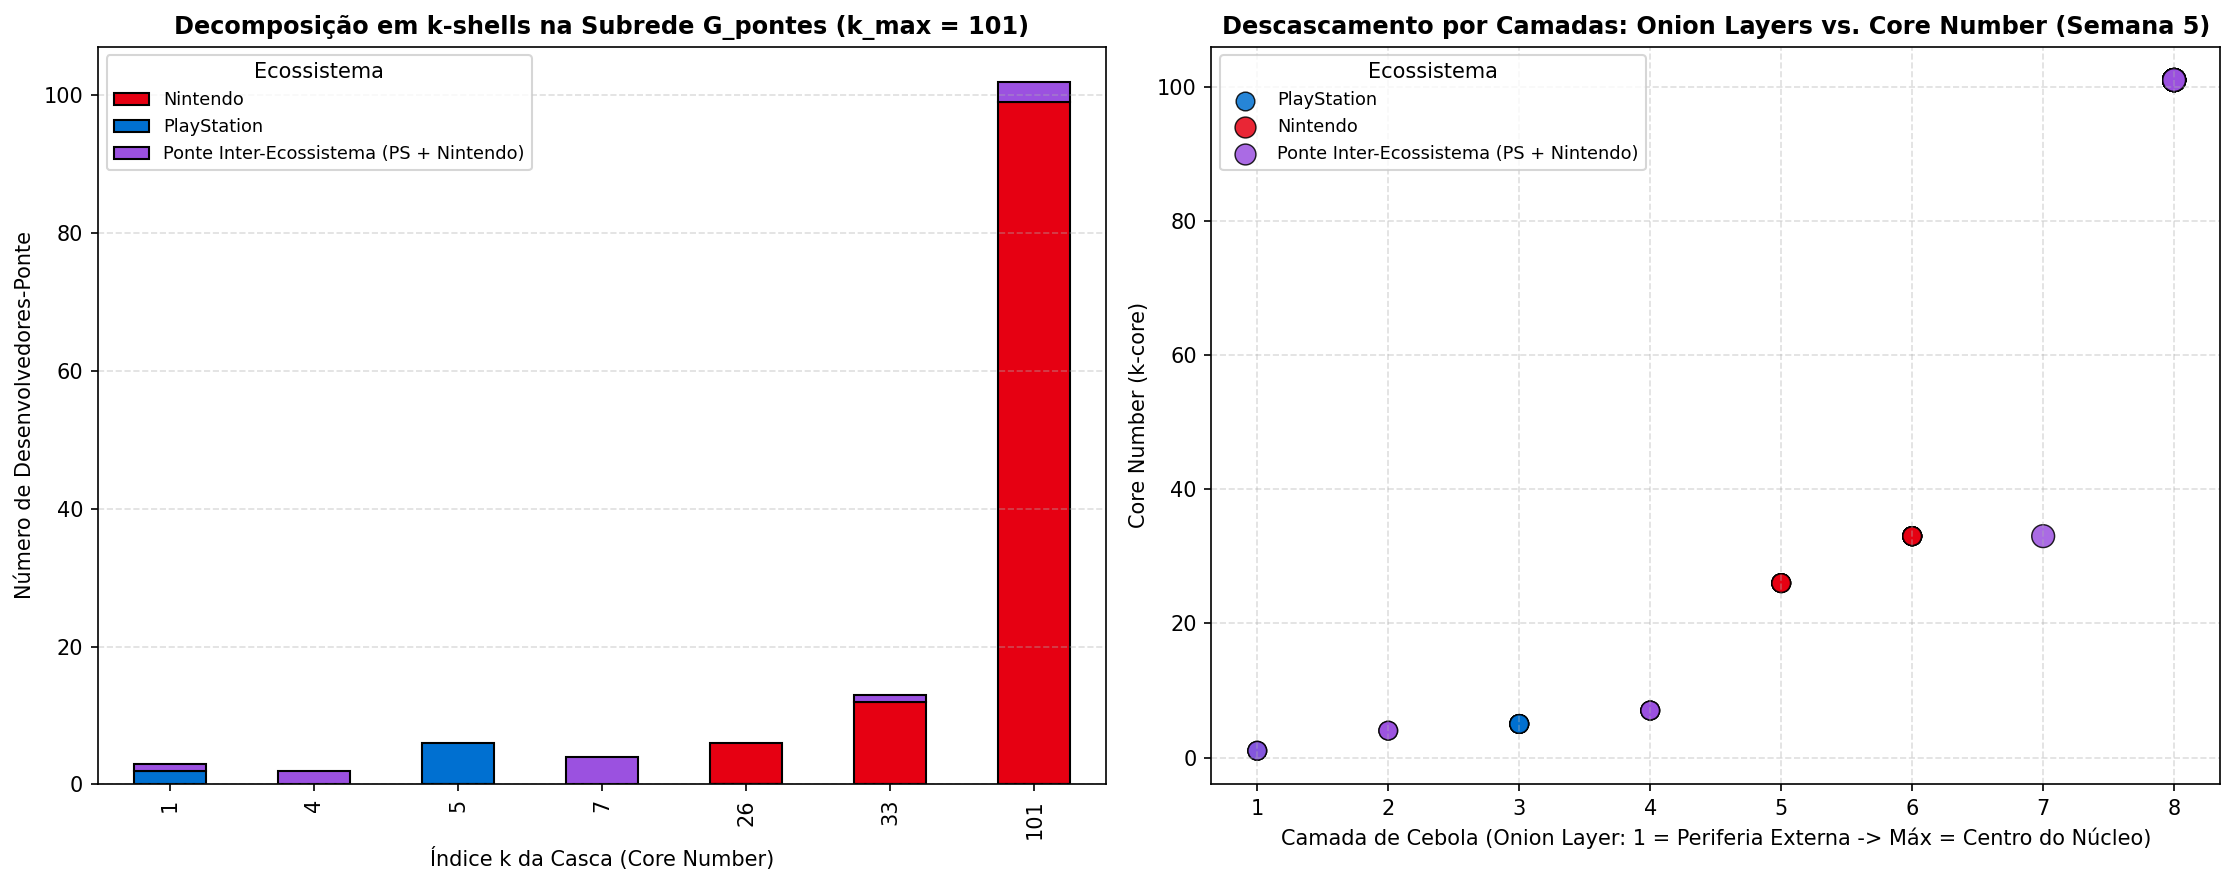

In [ ]:
# 3.3 DECOMPOSIÇÃO EM NÚCLEOS: K-CORE, K-SHELL, DEGENERACY E ONION LAYERS

# Removendo eventuais auto-laços por segurança antes de rodar k-core / onion_layers
G_pontes_limpo = G_pontes.copy()
G_pontes_limpo.remove_edges_from(nx.selfloop_edges(G_pontes_limpo))

# 1. Core Number e Degeneracy (k_max) [Semana 5]
core_numbers = nx.core_number(G_pontes_limpo)
degeneracy_kmax = max(core_numbers.values()) if core_numbers else 0

# 2. Onion Layers (Camadas de Cebola - refina a ordem de descascamento dentro de cada k-shell) [Semana 5]
onion_layers = nx.onion_layers(G_pontes_limpo)

# 3. Extraindo o Núcleo Máximo (Main k-core, k = k_max) e a casca principal (k-shell)
G_main_kcore = nx.k_core(G_pontes_limpo, k=degeneracy_kmax)
G_main_kshell = nx.k_shell(G_pontes_limpo, k=degeneracy_kmax)

# Salvando nos atributos de G_pontes
nx.set_node_attributes(G_pontes, core_numbers, name="core_number")
nx.set_node_attributes(G_pontes, onion_layers, name="onion_layer")

print("----------------------------------------------------------------------")
print("RESUMO DA DECOMPOSIÇÃO EM NÚCLEOS NA SUBREDE G_pontes (SEMANA 5):")
print(f"• Degenerescência (Degeneracy / k_max): k = {degeneracy_kmax}")
print(f"• Tamanho do Núcleo Máximo ({degeneracy_kmax}-core): {G_main_kcore.number_of_nodes()} nós e {G_main_kcore.number_of_edges()} arestas")
print(f"• Total de Camadas de Cebola (Onion Layers): {max(onion_layers.values())} camadas distintas")
print("----------------------------------------------------------------------")

# Tabela de distribuição dos k-shells em G_pontes
resumo_kshells = (
    pd.DataFrame([
        {
            "Nó": n,
            "Desenvolvedor": G_pontes.nodes[n].get("name", str(n)),
            "k-shell (Core Number)": core_numbers[n],
            "Onion Layer": onion_layers[n],
            "Perfil Ecossistema": G_pontes.nodes[n].get("perfil_eco", "N/A"),
            "Nº Emuladores": G_pontes.nodes[n].get("num_repos", 2)
        }
        for n in G_pontes.nodes()
    ])
)

dist_shells = (
    resumo_kshells.groupby("k-shell (Core Number)")
    .agg(
        Quantidade_Devs=("Nó", "count"),
        Camadas_Onion=("Onion Layer", lambda s: f"{min(s)} a {max(s)}"),
        Perfis_Predominantes=("Perfil Ecossistema", lambda s: ", ".join(f"{k}: {v}" for k, v in s.value_counts().items())),
        Exemplos_Devs=("Desenvolvedor", lambda s: ", ".join(list(s)[:4]))
    )
    .reset_index()
    .sort_values(by="k-shell (Core Number)", ascending=False)
)

print("\n=== HIERARQUIA DE CASCAS (K-SHELLS) E CAMADAS (ONION LAYERS) EM G_pontes ===")
display(dist_shells)

# GRÁFICO: DECOMPOSIÇÃO K-CORE E ONION LAYERS (NÚCLEO vs. PERIFERIA)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Painel Esquerdo: Distribuição de Devs por k-shell colorido por Ecossistema
tabela_pivot = pd.crosstab(resumo_kshells["k-shell (Core Number)"], resumo_kshells["Perfil Ecossistema"])
cores_barras = [CORES_PERFIL.get(col, "#888888") for col in tabela_pivot.columns]
tabela_pivot.plot(kind="bar", stacked=True, color=cores_barras, edgecolor="black", ax=axes[0])

axes[0].set_title(f"Decomposição em k-shells na Subrede G_pontes (k_max = {degeneracy_kmax})", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Índice k da Casca (Core Number)", fontsize=10)
axes[0].set_ylabel("Número de Desenvolvedores-Ponte", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend(title="Ecossistema", frameon=True, fontsize=8.5)

# Painel Direito: Relação entre Onion Layer (Profundidade Estrutural) e Core Number
for perfil, cor in CORES_PERFIL.items():
    sub = resumo_kshells[resumo_kshells["Perfil Ecossistema"] == perfil]
    axes[1].scatter(
        sub["Onion Layer"],
        sub["k-shell (Core Number)"],
        s=sub["Nº Emuladores"] * 40,
        c=cor, label=perfil, alpha=0.85, edgecolors="black", linewidth=0.7
    )

axes[1].set_title("Descascamento por Camadas: Onion Layers vs. Core Number (Semana 5)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Camada de Cebola (Onion Layer: 1 = Periferia Externa -> Máx = Centro do Núcleo)", fontsize=10)
axes[1].set_ylabel("Core Number (k-core)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(title="Ecossistema", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.savefig("figuras/5_decomposicao_kcore_onion_layers.png", dpi=150)
plt.show()

A aplicação da decomposição em núcleos e a análise da topologia Núcleo-Periferia sobre a subrede `G_pontes` revelam como a hierarquia de coesão estrutural reflete com exatidão matemática o tamanho das interseções entre os repositórios de emuladores:

#### 1. Degenerescência ($k_{\max} = 101$) e a Identidade Matemática das Cascas ($k = N - 1$)
O grafo `G_pontes` apresenta **degenerescência $k_{\max} = 101$**, particionando os desenvolvedores-ponte em **7 cascas (`k-shells`) distintas**: $k \in \{101, 33, 26, 7, 5, 4, 1\}$. Ao cruzarmos esses índices com a tabela de sobreposição de repositórios (`arestas_repos_df` da Seção 2), constatamos que cada casca $k$ corresponde exatamente a $N - 1$, onde $N$ é o número de desenvolvedores compartilhados por um par específico de emuladores (que gera uma clique $K_N$ de grau interno $N - 1$):

* **Núcleo Máximo (`101-core` / Camada 8 — `102` devs e `5.151` arestas):** Corresponde exatamente aos desenvolvedores compartilhados entre `azahar` e `citron-neo` ($102 - 1 = 101$). O número de arestas no subgrafo induzido ($\binom{102}{2} = \frac{102 \times 101}{2} = 5.151$) comprova que o coração da rede é uma clique completa perfeita ($K_{102}$) que concentra 75% dos nós e 90,5% das arestas de toda a subrede de pontes. Ele é composto por `99` desenvolvedores exclusivos da Nintendo e pelos `3` principais *brokers* Inter-Ecossistema (`raphaelthegreat`, `N00byKing` e `abouvier`, que atuam em `azahar + citron-neo + shadPS4`).
* **Casca Intermediária Alta (`33-shell` / Camadas 6 e 7 — `13` devs):** Reflete os 34 desenvolvedores em comum entre `azahar` e `dolphin`. Como 21 desses desenvolvedores contribuem nos 3 emuladores da Nintendo e já foram alocados no `101-core`, restam nesta casca exatamente 13 desenvolvedores: 12 exclusivos da dupla `azahar + dolphin` e 1 Ponte Inter-Ecossistema (`oltolm`, atuante em `azahar + dolphin + shadPS4`).
* **Casca Intermediária Média (`26-shell` / Camada 5 — `6` devs):** Reflete os em comum entre `citron-neo` e `dolphin`. Descontando os mesmos 21 membros da tríade Nintendo presentes no núcleo máximo, restam exatamente os 6 desenvolvedores ($27 - 21 = 6$) exclusivos do par `citron-neo + dolphin` (`CrossVR`, `FireBurn`, `K0bin`, `maxdunbar`, etc.).
* **Cascas de Fronteira e Periferia ($k \in \{7, 5, 4, 1\}$ / Camadas 1 a 4 — `15` devs):**
  * **`7-shell` (4 devs):** Derivada dos devs comuns entre `azahar` e `shadPS4`. Descontados os 4 que atuam em 3 projetos (`raphaelthegreat`, `N00byKing`, `abouvier` e `oltolm`), restam as 4 pontes exclusivas do par `azahar + shadPS4` (`Masamune3210`, `sammiq`, `smiRaphi` e `wheremyfoodat`).
  * **`5-shell` (6 devs):** Corresponde à Componente 2 isolada da PlayStation (`KytyPS5 + shadPS4`, com `Aspenini`, `C0rn3j`, `Hultwl`, `Kody-Schram`, etc.).
  * **`4-shell` (2 devs):** Derivada dos 5 devs comuns entre `citron-neo` e `shadPS4`. Descontados os 3 presentes no `101-core`, restam `DanielSvoboda` e `makigumo`.
  * **`1-shell` (3 devs):** Reúne as interseções de apenas 2 desenvolvedores, compreendendo a dupla da PlayStation de `InoriRus/Kyty + shadPS4` (`AboMedoz` e `Mored4u`, Componente 3) e a ponte `slick-daddy` (`dolphin + shadPS4`).

#### 2. O Ganho Analítico das Camadas de Cebola (*Onion Layers*) sobre o `k-shell`
A comparação entre o gráfico de barras (`k-shells`) e o gráfico de dispersão (*Onion Layers vs. Core Number*) evidencia a utilidade prática da decomposição em camadas de cebola: embora existam **7 `k-shells`**, o algoritmo identifica **8 `Onion Layers`**.
* Especificamente dentro da casca **`k-shell = 33`**, a decomposição *Onion Layers* separa os nós em duas camadas sucessivas: a **Camada 6** (ocupada pelos `12` desenvolvedores exclusivos da Nintendo em `azahar + dolphin`, ponto vermelho) e a **Camada 7** (ocupada pelo desenvolvedor Ponte Inter-Ecossistema `oltolm`, ponto roxo).
* Isso ocorre porque o descascamento por camadas (*peeling*) registra a ordem exata em que os nós atingem o limiar de corte: quando os 12 desenvolvedores de `azahar + dolphin` são removidos na primeira passagem do grau 33 (Camada 6), `oltolm` sobrevive por uma iteração adicional graças à sua conectividade suplementar oriunda do ecossistema PlayStation (`shadPS4`), posicionando-se em uma camada mais interna (Camada 7).

#### 3. Estrutura Núcleo-Periferia: Coesão vs. Corretagem

A síntese conjunta das centralidades (Seção 3.2) com a decomposição em núcleos (Seção 3.3) demonstra uma clara estrutura Núcleo-Periferia:
1. **Assimetria entre os Ecossistemas:** O ecossistema *Nintendo* constitui um núcleo hiperdenso ($k \in \{26, 33, 101\}$, Camadas 5 a 8), fruto do compartilhamento massivo de contribuidores entre `azahar`, `citron-neo` e `dolphin`. Em contrapartida, o ecossistema **PlayStation** situa-se inteiramente nas cascas periféricas ($k \in \{1, 5\}$, Camadas 1 e 3), refletindo comunidades menores e mais isoladas entre si.
2. **Vulnerabilidade Estrutural das Pontes:** Dos 11 desenvolvedores que conectam os ecossistemas PlayStation e Nintendo em `G_pontes`, 8 estão localizados fora do núcleo máximo ($k \in \{1, 4, 7, 33\}$). Isso confirma um princípio fundamental da Ciência das Redes: **nós periféricos em termos de $k$-core (baixa coesão local) frequentemente desempenham papéis vitais de intermediação global (*Betweenness*)**. Apenas o trio `raphaelthegreat`, `N00byKing` e `abouvier` reúne simultaneamente a máxima centralidade de núcleo (`101-core`, Camada 8) e a máxima intermediação entre os dois ecossistemas.

# 4. Conclusão, Resposta à Pergunta Central e Limitações

A combinação das representações em **Rede Bipartida (`B`)**, **Projeção Unipartida Bruta (`G_bruto`)**, **Esqueleto por Limiar (`G_pontes`, $w \ge 2$)** e **Projeção de Repositórios (`G_repos`)**, analisada sob as métricas das **Semanas 2 a 6**, permite responder de forma quantitativa e calibrada à pergunta central deste projeto:

> *"Há sobreposição de desenvolvedores entre projetos de emulação e, em caso afirmativo, como ela é estruturada e quais os principais contribuidores/projetos que atuam como ponte?"*

---

## 4.1 Resposta Direta e Conclusão Calibrada

### 1. Há sobreposição de desenvolvedores entre os projetos?
**Sim, mas ela é fortemente concentrada em uma minoria estratégica.** Dos **957 desenvolvedores ativos** (com $\ge 10$ estrelas) mapeados nas 1.119 relações de contribuição, **820 desenvolvedores (85,7%)** contribuíram em apenas um único emulador, enquanto **137 desenvolvedores (14,3%)** atuaram em múltiplos projetos (`multi_repo == 1`). Embora minoritários em volume, esses `137` desenvolvedores-ponte são suficientes para integrar **100% da rede em uma única Componente Gigante (`WCC = 1` em `B` e `G_bruto`)**, garantindo uma topologia de **Mundo Pequeno** com **diâmetro igual a 3** (qualquer desenvolvedor está a no máximo 3 saltos de co-atuação de qualquer outro).

### 2. Como essa sobreposição é estruturada? (Assimetria Núcleo-Periferia)
A sobreposição apresenta uma **forte assimetria estrutural** entre os dois ecossistemas analisados:
* **Coesão Hiperdensa no Ecossistema Nintendo (O Núcleo):** Os projetos da Nintendo (`azahar`, `citron-neo` e `dolphin`) possuem altíssima integração mútua. A interseção entre `azahar` e `citron-neo` compartilha **102 desenvolvedores** (`Índice de Jaccard = 0,2318`), formando uma clique completa perfeita que origina o **Núcleo Máximo da subrede (`101-core` / Camada de Cebola 8)**, concentrando sozinho **75% dos nós** e **90,5% das arestas** de `G_pontes`. O emulador `dolphin` acopla-se fortemente a esse núcleo, compartilhando **34 desenvolvedores** com `azahar` (`33-shell`, `Jaccard = 0,0606`) e **27** com `citron-neo` (`26-shell`, `Jaccard = 0,0597`). No domínio técnico, isso reflete o histórico compartilhado de arquiteturas ARM/C++ e *forks* derivados de bases comuns nas comunidades de Nintendo 3DS, GameCube/Wii e Switch.
* **Isolamento Interno e Periférico no Ecossistema PlayStation (A Periferia):** Em contraste, o ecossistema PlayStation (`shadPS4`, `KytyPS5` e `InoriRus/Kyty`) mostra-se fragmentado tanto em relação à Nintendo quanto **internamente entre seus próprios projetos**. Na decomposição em núcleos de `G_pontes`, os desenvolvedores exclusivos da PlayStation situam-se inteiramente nas cascas mais externas (`5-shell` com 6 devs entre `KytyPS5` e `shadPS4`, e `1-shell` com 2 devs entre `Kyty` e `shadPS4`), formando duas componentes isoladas (Componentes 2 e 3) quando exigimos co-ocorrência múltipla ($w \ge 2$). Além disso, os projetos `InoriRus/Kyty` e `KytyPS5` apresentam **zero desenvolvedores em comum** na amostra coletada.
* **Fragilidade da Conexão Inter-Ecossistema:** A união entre os mundos PlayStation e Nintendo não é difusa, mas sustentada por uma **ponte estreita de apenas 12 desenvolvedores inter-ecossistema** (11 em `G_pontes` e 1 ponte solitária de peso $w=1$).

### 3. Quais são os principais projetos e contribuidores que atuam como ponte?
* **Projetos-Ponte:**
  1. **`azahar-emu/azahar` (Ponte Global e Hub Nintendo):** É o único repositório com grau máximo na projeção de emuladores ($d = 5$ em `G_repos`), conectando-se a todos os outros 5 projetos analisados.
  2. **`shadps4-emu/shadPS4` (Principal Porta de Entrada da PlayStation):** Atua como o grande concentrador do lado PlayStation, estabelecendo conexões com todos os três emuladores da Nintendo (`8` devs com `azahar`, `5` com `citron-neo` e `2` com `dolphin`), além de manter as únicas ligações com `KytyPS5` (`6` devs) e `InoriRus/Kyty` (`2` devs).
* **Contribuidores-Ponte (Brokers vs. Hubs):**
  1. **Principais Pontes Inter-Ecossistema (*Brokers* Globais por *Betweenness*):** O trio **`raphaelthegreat`**, **`N00byKing`** e **`abouvier`** (atuantes simultaneamente em `azahar`, `citron-neo` e `shadPS4`) detém a maior centralidade de intermediação nas projeções (`Betweenness = 0,04650` em $w \ge 1$ e `0,02427` em $w \ge 2$), seguido por **`oltolm`** (`0,02824` em $w \ge 1$, atuando em `azahar`, `dolphin` e `shadPS4`). Na rede bipartida ponderada (`B`), **`raphaelthegreat`** destaca-se isoladamente com **`Betweenness = 0,42743`**, provando ser o conector técnico mais prolífico entre os ecossistemas PlayStation e Nintendo.
  2. **Principais Articuladores Internos da Nintendo (Hubs de Núcleo por *Eigenvector* e *Bipartida*):** Desenvolvedores que atuam na tríade `azahar + citron-neo + dolphin` — com destaque para **`lioncash`** (`Betweenness = 0,38724` na rede bipartida `B`), **`CarlKenner`**, **`CookiePLMonster`**, **`KAMiKAZOW`**, **`v1993`** e **`yuriks`** — atingem o teto de influência no núcleo denso (`Eigenvector = 0,11004` e `Degree Centrality = 0,8889` em `G_pontes`).

---

## 4.2 Limitações e Artefatos Reconhecidos

Para uma leitura rigorosa dos resultados, reconhecemos três categorias principais de limitações e artefatos metodológicos:

1. **Artefatos de Projeção e Equivalência Estrutural (Semana 6):**
   * *Explosão de Cliques e Triângulos:* A projeção unipartida bruta (`G_bruto`) transforma cada repositório de tamanho $n$ em uma clique completa $K_n$, inflando artificialmente a rede para **128.260 arestas**, densidade de `0,2804` e **11.582.259 triângulos** (`Clustering = 0,9502`). Esse artefato mascara quem realmente colabora em múltiplos projetos, razão pela qual o **Esqueleto por Limiar ($w \ge 2$)** e a **Rede Bipartida (`B`)** foram indispensáveis.
   * *Empates por Equivalência Estrutural e Poda de Pontes Solitárias:* Na projeção por co-ocorrência, todos os desenvolvedores que atuam no mesmo subconjunto de emuladores recebem pesos idênticos e empatam nas métricas topológicas. Além disso, o corte rígido $w \ge 2$ em `G_pontes` desconecta pontes legítimas que compartilham apenas 1 emulador com outros colegas-ponte (como o 137º desenvolvedor-ponte entre `Kyty` e `azahar` e as ligações das Componentes 2 e 3 com o `shadPS4`), o que foi corrigido ao cruzarmos a análise com `G_pontes_w1` e `B`.
2. **Viés de Amostragem e Recorte Temporal (Janela da API e Filtro de Estrelas):**
   * *Teto de Paginação (10 páginas / até 1.000 registros por endpoint):* Em repositórios históricos e massivos como o `dolphin-emu/dolphin`, o limite da API do GitHub captura a **comunidade ativa recente**, sub-representando contribuidores antigos que poderiam ter migrado anos atrás para outros projetos.
   * *Filtro de Engajamento ($\ge 10$ repositórios favoritados):* A exigência de ao menos 10 *stars* no perfil foi eficaz para eliminar *bots* e contas fantasmas, reduzindo a rede de `1.166` para `957` desenvolvedores engajados, mas pode ter descartado desenvolvedores experientes que simplesmente não têm o hábito de favoritar repositórios no GitHub.
3. **Dados Faltantes e Fronteira do Domínio (O que ficou de fora):**
   * *Interações fora do GitHub:* Grande parte da colaboração arquitetural entre desenvolvedores de emuladores (como discussões sobre engenharia reversa, tradução de *shaders* Vulkan e *debugging*) ocorre em servidores do **Discord**, fóruns especializados e canais de IRC, que não deixam rastro direto na API do GitHub.
   * *Agregação de Tipos de Ação:* Na projeção `G_bruto`, um usuário que reportou *issues* detalhadas e um engenheiro que submeteu *pull requests* de código C++ geram a mesma aresta de co-ocorrência. Embora tenhamos mitigado isso atribuindo peso dobrado aos *pull requests* na Rede Bipartida `B`, análises futuras podem separar redes exclusivas de código (*commits/PRs*) de redes de teste/relato (*issues*).

---

## 4.3 Próximos Passos Concretos

Com base nas evidências obtidas, propomos três desdobramentos práticos para a comunidade e para a continuidade do estudo:
1. **Para Mantenedores de Emuladores (Fomento de Colaboração Técnica):** Utilizar os *brokers* identificados (`raphaelthegreat`, `oltolm`, `N00byKing`, `abouvier`) como elos para criação de bibliotecas compartilhadas em C++ (ex.: recompiladores de *shaders* SPIR-V/Vulkan e camadas de abstração de áudio/controle), reduzindo o isolamento técnico de projetos menores da PlayStation (`KytyPS5`) em relação ao ecossistema maduro da Nintendo.
2. **Refinamento Metodológico (Projeção Bipartida Hiperbólica / *Backbone* Estatístico):** Substituir o corte por limiar fixo ($w \ge 2$) por métodos estatísticos de extração de *backbone* (como o *Disparity Filter* de Serrano et al. ou projeções ponderadas de Newman, onde repositórios maiores contribuem com peso fracionário $\frac{1}{N_{\text{repo}} - 1}$), preservando pontes de repositórios pequenos como `InoriRus/Kyty` sem precisar descartar arestas $w = 1$.
3. **Análise Temporal e Direcionada de Migração:** Expandir a coleta com *timestamps* das interações para construir um **dígrafo temporal**, permitindo responder não apenas *quem* atua como ponte, mas *qual a direção do fluxo de conhecimento* (ex.: verificar se os desenvolvedores amadurecem primeiro no `Dolphin`/`Azahar` e posteriormente migram para o `shadPS4`).